# Story 1 — Does Neighborhood Sanitation Reflect Restaurant Food Safety?

**Research question:** Do Chicago ZIP codes with more recorded 311 sanitation complaints also have higher *graded food-inspection* failure rates?

**Scope:** ZIP-level ecological comparisons; 2011–2025. **Important:** These ZIP-level measures are not per-capita rates, the complaints are not necessarily restaurant-specific, and correlation is not causation. Only ZIPs with at least 500 graded inspections across these years are included in ZIP rankings.

## Setup and embedded verified aggregates

All figures below are computed from **aggregated results derived from the five user-provided Chicago ZIP archives**, with duplicate request IDs and inspection IDs removed. Figures are embedded in this executed notebook and can be recalculated **without uploading raw ZIPs**. All estimates refer to **2011–2025 complete comparison years**, unless explicitly noted. See the README for methodology. ZIP codes are only proxies for neighborhoods; same ZIP/address is not proof a 311 complaint relates to a specific food establishment.

In [1]:
import json
import builtins
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(9.3,4.6),'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','font.size':10})
BLUE='#28679c'; TEAL='#18877b'; ORANGE='#e19531'; RED='#c95756'; GREY='#7c8791'
def pct(x, n): return 100*x/n if n else np.nan
def style(ax, title, ylabel=None, xlabel=None):
    ax.set_title(title,loc='left',pad=14,fontsize=12)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    ax.grid(axis='y',alpha=.18)
    ax.set_axisbelow(True)
    plt.tight_layout()
def show():
    plt.show()

zip = pd.DataFrame(json.loads(r'''[{"zip":"60601","complaints":292,"graded":4142,"fails":556,"fail_pct":13.4235},{"zip":"60602","complaints":207,"graded":1763,"fails":289,"fail_pct":16.3925},{"zip":"60603","complaints":145,"graded":2290,"fails":364,"fail_pct":15.8952},{"zip":"60604","complaints":98,"graded":1504,"fails":235,"fail_pct":15.625},{"zip":"60605","complaints":680,"graded":3843,"fails":827,"fail_pct":21.5196},{"zip":"60606","complaints":191,"graded":3799,"fails":525,"fail_pct":13.8194},{"zip":"60607","complaints":1591,"graded":6967,"fails":1516,"fail_pct":21.7597},{"zip":"60608","complaints":5909,"graded":7450,"fails":1751,"fail_pct":23.5034},{"zip":"60609","complaints":6146,"graded":5058,"fails":1104,"fail_pct":21.8268},{"zip":"60610","complaints":2053,"graded":4907,"fails":959,"fail_pct":19.5435},{"zip":"60611","complaints":565,"graded":8097,"fails":1401,"fail_pct":17.3027},{"zip":"60612","complaints":5215,"graded":4008,"fails":889,"fail_pct":22.1806},{"zip":"60613","complaints":2463,"graded":5408,"fails":1081,"fail_pct":19.9889},{"zip":"60614","complaints":8139,"graded":8968,"fails":2085,"fail_pct":23.2493},{"zip":"60615","complaints":2345,"graded":2929,"fails":772,"fail_pct":26.3571},{"zip":"60616","complaints":2823,"graded":6449,"fails":1515,"fail_pct":23.492},{"zip":"60617","complaints":9633,"graded":4859,"fails":1226,"fail_pct":25.2315},{"zip":"60618","complaints":8141,"graded":7396,"fails":1381,"fail_pct":18.6723},{"zip":"60619","complaints":11265,"graded":4799,"fails":1446,"fail_pct":30.1313},{"zip":"60620","complaints":11695,"graded":4658,"fails":1346,"fail_pct":28.8965},{"zip":"60621","complaints":5767,"graded":2074,"fails":581,"fail_pct":28.0135},{"zip":"60622","complaints":5736,"graded":7402,"fails":1700,"fail_pct":22.9668},{"zip":"60623","complaints":6783,"graded":5551,"fails":1469,"fail_pct":26.4637},{"zip":"60624","complaints":5772,"graded":2486,"fails":648,"fail_pct":26.066},{"zip":"60625","complaints":4709,"graded":6717,"fails":1628,"fail_pct":24.237},{"zip":"60626","complaints":2560,"graded":3795,"fails":946,"fail_pct":24.9275},{"zip":"60628","complaints":10875,"graded":4360,"fails":1271,"fail_pct":29.1514},{"zip":"60629","complaints":7853,"graded":4690,"fails":1013,"fail_pct":21.5991},{"zip":"60630","complaints":3599,"graded":3287,"fails":706,"fail_pct":21.4786},{"zip":"60631","complaints":1233,"graded":1833,"fails":363,"fail_pct":19.8036},{"zip":"60632","complaints":7327,"graded":5762,"fails":1252,"fail_pct":21.7286},{"zip":"60634","complaints":4659,"graded":4708,"fails":884,"fail_pct":18.7766},{"zip":"60636","complaints":7729,"graded":2710,"fails":760,"fail_pct":28.0443},{"zip":"60637","complaints":5367,"graded":2943,"fails":780,"fail_pct":26.5036},{"zip":"60638","complaints":3476,"graded":3363,"fails":508,"fail_pct":15.1056},{"zip":"60639","complaints":6450,"graded":6504,"fails":1762,"fail_pct":27.091},{"zip":"60640","complaints":3505,"graded":6639,"fails":1543,"fail_pct":23.2415},{"zip":"60641","complaints":5067,"graded":4226,"fails":838,"fail_pct":19.8296},{"zip":"60642","complaints":2483,"graded":3047,"fails":624,"fail_pct":20.4792},{"zip":"60643","complaints":5331,"graded":3533,"fails":795,"fail_pct":22.5021},{"zip":"60644","complaints":5970,"graded":2906,"fails":791,"fail_pct":27.2195},{"zip":"60645","complaints":2999,"graded":1731,"fails":422,"fail_pct":24.379},{"zip":"60646","complaints":1741,"graded":1742,"fails":321,"fail_pct":18.4271},{"zip":"60647","complaints":9073,"graded":8792,"fails":2082,"fail_pct":23.6806},{"zip":"60649","complaints":5951,"graded":2817,"fails":659,"fail_pct":23.3937},{"zip":"60651","complaints":7530,"graded":3304,"fails":942,"fail_pct":28.5109},{"zip":"60652","complaints":3747,"graded":2149,"fails":375,"fail_pct":17.45},{"zip":"60653","complaints":2588,"graded":2115,"fails":482,"fail_pct":22.7896},{"zip":"60654","complaints":625,"graded":5630,"fails":1005,"fail_pct":17.8508},{"zip":"60655","complaints":1024,"graded":1089,"fails":193,"fail_pct":17.7227},{"zip":"60656","complaints":1055,"graded":973,"fails":204,"fail_pct":20.9661},{"zip":"60657","complaints":4941,"graded":7982,"fails":1747,"fail_pct":21.8867},{"zip":"60659","complaints":3616,"graded":4893,"fails":1215,"fail_pct":24.8314},{"zip":"60660","complaints":1760,"graded":3738,"fails":924,"fail_pct":24.7191},{"zip":"60661","complaints":254,"graded":3303,"fails":547,"fail_pct":16.5607},{"zip":"60666","complaints":11,"graded":3504,"fails":423,"fail_pct":12.0719},{"zip":"60707","complaints":1430,"graded":1314,"fails":301,"fail_pct":22.9072}]'''))
zipyear = pd.DataFrame(json.loads(r'''[{"zip":"60601","year":2011,"complaints":20,"graded":312,"fails":44,"fail_pct":14.102564102564102},{"zip":"60601","year":2012,"complaints":11,"graded":251,"fails":34,"fail_pct":13.54581673306773},{"zip":"60601","year":2013,"complaints":17,"graded":319,"fails":36,"fail_pct":11.285266457680251},{"zip":"60601","year":2014,"complaints":28,"graded":336,"fails":38,"fail_pct":11.30952380952381},{"zip":"60601","year":2015,"complaints":24,"graded":312,"fails":35,"fail_pct":11.217948717948717},{"zip":"60601","year":2016,"complaints":39,"graded":346,"fails":45,"fail_pct":13.00578034682081},{"zip":"60601","year":2017,"complaints":26,"graded":388,"fails":88,"fail_pct":22.68041237113402},{"zip":"60601","year":2018,"complaints":31,"graded":306,"fails":20,"fail_pct":6.5359477124183005},{"zip":"60601","year":2019,"complaints":9,"graded":246,"fails":30,"fail_pct":12.195121951219512},{"zip":"60601","year":2020,"complaints":11,"graded":209,"fails":40,"fail_pct":19.138755980861244},{"zip":"60601","year":2021,"complaints":21,"graded":205,"fails":10,"fail_pct":4.878048780487805},{"zip":"60601","year":2022,"complaints":11,"graded":222,"fails":41,"fail_pct":18.46846846846847},{"zip":"60601","year":2023,"complaints":22,"graded":210,"fails":15,"fail_pct":7.142857142857143},{"zip":"60601","year":2024,"complaints":13,"graded":234,"fails":14,"fail_pct":5.982905982905983},{"zip":"60601","year":2025,"complaints":9,"graded":246,"fails":66,"fail_pct":26.829268292682926},{"zip":"60602","year":2011,"complaints":14,"graded":129,"fails":17,"fail_pct":13.178294573643411},{"zip":"60602","year":2012,"complaints":12,"graded":100,"fails":27,"fail_pct":27.0},{"zip":"60602","year":2013,"complaints":22,"graded":130,"fails":18,"fail_pct":13.846153846153847},{"zip":"60602","year":2014,"complaints":19,"graded":134,"fails":16,"fail_pct":11.940298507462687},{"zip":"60602","year":2015,"complaints":35,"graded":141,"fails":26,"fail_pct":18.43971631205674},{"zip":"60602","year":2016,"complaints":19,"graded":152,"fails":22,"fail_pct":14.473684210526315},{"zip":"60602","year":2017,"complaints":27,"graded":181,"fails":26,"fail_pct":14.3646408839779},{"zip":"60602","year":2018,"complaints":21,"graded":116,"fails":12,"fail_pct":10.344827586206897},{"zip":"60602","year":2019,"complaints":5,"graded":105,"fails":15,"fail_pct":14.285714285714286},{"zip":"60602","year":2020,"complaints":6,"graded":101,"fails":30,"fail_pct":29.702970297029704},{"zip":"60602","year":2021,"complaints":9,"graded":70,"fails":4,"fail_pct":5.714285714285714},{"zip":"60602","year":2022,"complaints":5,"graded":105,"fails":26,"fail_pct":24.761904761904763},{"zip":"60602","year":2023,"complaints":6,"graded":89,"fails":17,"fail_pct":19.10112359550562},{"zip":"60602","year":2024,"complaints":3,"graded":104,"fails":8,"fail_pct":7.6923076923076925},{"zip":"60602","year":2025,"complaints":4,"graded":106,"fails":25,"fail_pct":23.58490566037736},{"zip":"60603","year":2011,"complaints":8,"graded":142,"fails":20,"fail_pct":14.084507042253522},{"zip":"60603","year":2012,"complaints":5,"graded":127,"fails":28,"fail_pct":22.04724409448819},{"zip":"60603","year":2013,"complaints":9,"graded":180,"fails":24,"fail_pct":13.333333333333334},{"zip":"60603","year":2014,"complaints":6,"graded":148,"fails":18,"fail_pct":12.162162162162161},{"zip":"60603","year":2015,"complaints":15,"graded":207,"fails":42,"fail_pct":20.28985507246377},{"zip":"60603","year":2016,"complaints":9,"graded":247,"fails":24,"fail_pct":9.7165991902834},{"zip":"60603","year":2017,"complaints":6,"graded":230,"fails":37,"fail_pct":16.08695652173913},{"zip":"60603","year":2018,"complaints":17,"graded":188,"fails":43,"fail_pct":22.872340425531913},{"zip":"60603","year":2019,"complaints":8,"graded":142,"fails":17,"fail_pct":11.971830985915492},{"zip":"60603","year":2020,"complaints":12,"graded":87,"fails":24,"fail_pct":27.586206896551722},{"zip":"60603","year":2021,"complaints":19,"graded":86,"fails":1,"fail_pct":1.1627906976744187},{"zip":"60603","year":2022,"complaints":6,"graded":120,"fails":23,"fail_pct":19.166666666666668},{"zip":"60603","year":2023,"complaints":13,"graded":126,"fails":28,"fail_pct":22.22222222222222},{"zip":"60603","year":2024,"complaints":7,"graded":129,"fails":8,"fail_pct":6.2015503875969},{"zip":"60603","year":2025,"complaints":5,"graded":131,"fails":27,"fail_pct":20.610687022900763},{"zip":"60604","year":2011,"complaints":2,"graded":123,"fails":14,"fail_pct":11.382113821138212},{"zip":"60604","year":2012,"complaints":2,"graded":89,"fails":14,"fail_pct":15.730337078651685},{"zip":"60604","year":2013,"complaints":9,"graded":108,"fails":14,"fail_pct":12.962962962962964},{"zip":"60604","year":2014,"complaints":5,"graded":118,"fails":17,"fail_pct":14.40677966101695},{"zip":"60604","year":2015,"complaints":7,"graded":125,"fails":10,"fail_pct":8.0},{"zip":"60604","year":2016,"complaints":4,"graded":161,"fails":19,"fail_pct":11.801242236024844},{"zip":"60604","year":2017,"complaints":19,"graded":130,"fails":34,"fail_pct":26.153846153846153},{"zip":"60604","year":2018,"complaints":11,"graded":118,"fails":11,"fail_pct":9.322033898305085},{"zip":"60604","year":2019,"complaints":4,"graded":98,"fails":15,"fail_pct":15.306122448979592},{"zip":"60604","year":2020,"complaints":3,"graded":70,"fails":11,"fail_pct":15.714285714285714},{"zip":"60604","year":2021,"complaints":3,"graded":40,"fails":0,"fail_pct":0.0},{"zip":"60604","year":2022,"complaints":21,"graded":98,"fails":26,"fail_pct":26.53061224489796},{"zip":"60604","year":2023,"complaints":5,"graded":82,"fails":22,"fail_pct":26.829268292682926},{"zip":"60604","year":2024,"complaints":1,"graded":81,"fails":17,"fail_pct":20.987654320987655},{"zip":"60604","year":2025,"complaints":2,"graded":63,"fails":11,"fail_pct":17.46031746031746},{"zip":"60605","year":2011,"complaints":47,"graded":293,"fails":27,"fail_pct":9.215017064846416},{"zip":"60605","year":2012,"complaints":47,"graded":191,"fails":29,"fail_pct":15.18324607329843},{"zip":"60605","year":2013,"complaints":36,"graded":277,"fails":52,"fail_pct":18.772563176895307},{"zip":"60605","year":2014,"complaints":43,"graded":308,"fails":70,"fail_pct":22.727272727272727},{"zip":"60605","year":2015,"complaints":52,"graded":229,"fails":34,"fail_pct":14.847161572052402},{"zip":"60605","year":2016,"complaints":72,"graded":298,"fails":34,"fail_pct":11.409395973154362},{"zip":"60605","year":2017,"complaints":65,"graded":306,"fails":59,"fail_pct":19.281045751633986},{"zip":"60605","year":2018,"complaints":57,"graded":266,"fails":80,"fail_pct":30.075187969924812},{"zip":"60605","year":2019,"complaints":20,"graded":311,"fails":78,"fail_pct":25.080385852090032},{"zip":"60605","year":2020,"complaints":25,"graded":145,"fails":17,"fail_pct":11.724137931034482},{"zip":"60605","year":2021,"complaints":60,"graded":179,"fails":45,"fail_pct":25.139664804469273},{"zip":"60605","year":2022,"complaints":64,"graded":255,"fails":83,"fail_pct":32.549019607843135},{"zip":"60605","year":2023,"complaints":39,"graded":289,"fails":107,"fail_pct":37.0242214532872},{"zip":"60605","year":2024,"complaints":20,"graded":254,"fails":49,"fail_pct":19.291338582677167},{"zip":"60605","year":2025,"complaints":33,"graded":242,"fails":63,"fail_pct":26.03305785123967},{"zip":"60606","year":2011,"complaints":16,"graded":307,"fails":23,"fail_pct":7.49185667752443},{"zip":"60606","year":2012,"complaints":15,"graded":197,"fails":29,"fail_pct":14.720812182741117},{"zip":"60606","year":2013,"complaints":15,"graded":318,"fails":25,"fail_pct":7.861635220125786},{"zip":"60606","year":2014,"complaints":16,"graded":380,"fails":79,"fail_pct":20.789473684210527},{"zip":"60606","year":2015,"complaints":10,"graded":276,"fails":30,"fail_pct":10.869565217391305},{"zip":"60606","year":2016,"complaints":23,"graded":388,"fails":46,"fail_pct":11.855670103092784},{"zip":"60606","year":2017,"complaints":23,"graded":257,"fails":48,"fail_pct":18.67704280155642},{"zip":"60606","year":2018,"complaints":22,"graded":308,"fails":42,"fail_pct":13.636363636363637},{"zip":"60606","year":2019,"complaints":8,"graded":254,"fails":47,"fail_pct":18.503937007874015},{"zip":"60606","year":2020,"complaints":1,"graded":152,"fails":15,"fail_pct":9.868421052631579},{"zip":"60606","year":2021,"complaints":9,"graded":126,"fails":2,"fail_pct":1.5873015873015872},{"zip":"60606","year":2022,"complaints":9,"graded":255,"fails":80,"fail_pct":31.372549019607842},{"zip":"60606","year":2023,"complaints":8,"graded":175,"fails":29,"fail_pct":16.571428571428573},{"zip":"60606","year":2024,"complaints":8,"graded":210,"fails":11,"fail_pct":5.238095238095238},{"zip":"60606","year":2025,"complaints":8,"graded":196,"fails":19,"fail_pct":9.693877551020408},{"zip":"60607","year":2011,"complaints":93,"graded":340,"fails":47,"fail_pct":13.823529411764707},{"zip":"60607","year":2012,"complaints":74,"graded":307,"fails":23,"fail_pct":7.49185667752443},{"zip":"60607","year":2013,"complaints":100,"graded":374,"fails":50,"fail_pct":13.368983957219251},{"zip":"60607","year":2014,"complaints":117,"graded":593,"fails":189,"fail_pct":31.871838111298484},{"zip":"60607","year":2015,"complaints":138,"graded":548,"fails":142,"fail_pct":25.912408759124087},{"zip":"60607","year":2016,"complaints":132,"graded":642,"fails":160,"fail_pct":24.922118380062305},{"zip":"60607","year":2017,"complaints":120,"graded":561,"fails":164,"fail_pct":29.233511586452764},{"zip":"60607","year":2018,"complaints":120,"graded":531,"fails":110,"fail_pct":20.715630885122412},{"zip":"60607","year":2019,"complaints":86,"graded":468,"fails":107,"fail_pct":22.863247863247864},{"zip":"60607","year":2020,"complaints":101,"graded":295,"fails":35,"fail_pct":11.864406779661017},{"zip":"60607","year":2021,"complaints":152,"graded":321,"fails":67,"fail_pct":20.87227414330218},{"zip":"60607","year":2022,"complaints":128,"graded":495,"fails":92,"fail_pct":18.585858585858585},{"zip":"60607","year":2023,"complaints":62,"graded":515,"fails":127,"fail_pct":24.660194174757283},{"zip":"60607","year":2024,"complaints":67,"graded":451,"fails":72,"fail_pct":15.964523281596453},{"zip":"60607","year":2025,"complaints":101,"graded":526,"fails":131,"fail_pct":24.90494296577947},{"zip":"60608","year":2011,"complaints":404,"graded":575,"fails":121,"fail_pct":21.043478260869566},{"zip":"60608","year":2012,"complaints":329,"graded":349,"fails":84,"fail_pct":24.068767908309457},{"zip":"60608","year":2013,"complaints":421,"graded":422,"fails":54,"fail_pct":12.796208530805687},{"zip":"60608","year":2014,"complaints":484,"graded":575,"fails":131,"fail_pct":22.782608695652176},{"zip":"60608","year":2015,"complaints":645,"graded":613,"fails":145,"fail_pct":23.65415986949429},{"zip":"60608","year":2016,"complaints":561,"graded":641,"fails":178,"fail_pct":27.76911076443058},{"zip":"60608","year":2017,"complaints":461,"graded":600,"fails":167,"fail_pct":27.833333333333332},{"zip":"60608","year":2018,"complaints":411,"graded":434,"fails":92,"fail_pct":21.19815668202765},{"zip":"60608","year":2019,"complaints":252,"graded":504,"fails":68,"fail_pct":13.492063492063492},{"zip":"60608","year":2020,"complaints":384,"graded":350,"fails":106,"fail_pct":30.285714285714285},{"zip":"60608","year":2021,"complaints":462,"graded":424,"fails":71,"fail_pct":16.745283018867923},{"zip":"60608","year":2022,"complaints":324,"graded":383,"fails":123,"fail_pct":32.114882506527415},{"zip":"60608","year":2023,"complaints":174,"graded":560,"fails":186,"fail_pct":33.214285714285715},{"zip":"60608","year":2024,"complaints":306,"graded":502,"fails":125,"fail_pct":24.900398406374503},{"zip":"60608","year":2025,"complaints":291,"graded":518,"fails":100,"fail_pct":19.305019305019304},{"zip":"60609","year":2011,"complaints":527,"graded":605,"fails":150,"fail_pct":24.793388429752067},{"zip":"60609","year":2012,"complaints":465,"graded":423,"fails":109,"fail_pct":25.768321513002363},{"zip":"60609","year":2013,"complaints":424,"graded":308,"fails":64,"fail_pct":20.77922077922078},{"zip":"60609","year":2014,"complaints":414,"graded":377,"fails":35,"fail_pct":9.283819628647215},{"zip":"60609","year":2015,"complaints":519,"graded":275,"fails":30,"fail_pct":10.909090909090908},{"zip":"60609","year":2016,"complaints":555,"graded":382,"fails":45,"fail_pct":11.780104712041885},{"zip":"60609","year":2017,"complaints":486,"graded":343,"fails":96,"fail_pct":27.988338192419825},{"zip":"60609","year":2018,"complaints":473,"graded":268,"fails":60,"fail_pct":22.388059701492537},{"zip":"60609","year":2019,"complaints":307,"graded":289,"fails":78,"fail_pct":26.98961937716263},{"zip":"60609","year":2020,"complaints":423,"graded":213,"fails":27,"fail_pct":12.67605633802817},{"zip":"60609","year":2021,"complaints":500,"graded":348,"fails":135,"fail_pct":38.793103448275865},{"zip":"60609","year":2022,"complaints":285,"graded":315,"fails":84,"fail_pct":26.666666666666668},{"zip":"60609","year":2023,"complaints":182,"graded":279,"fails":43,"fail_pct":15.412186379928315},{"zip":"60609","year":2024,"complaints":294,"graded":287,"fails":60,"fail_pct":20.905923344947734},{"zip":"60609","year":2025,"complaints":292,"graded":346,"fails":88,"fail_pct":25.433526011560694},{"zip":"60610","year":2011,"complaints":129,"graded":298,"fails":100,"fail_pct":33.557046979865774},{"zip":"60610","year":2012,"complaints":98,"graded":226,"fails":36,"fail_pct":15.929203539823009},{"zip":"60610","year":2013,"complaints":112,"graded":342,"fails":38,"fail_pct":11.11111111111111},{"zip":"60610","year":2014,"complaints":152,"graded":483,"fails":134,"fail_pct":27.74327122153209},{"zip":"60610","year":2015,"complaints":101,"graded":372,"fails":61,"fail_pct":16.397849462365592},{"zip":"60610","year":2016,"complaints":124,"graded":487,"fails":126,"fail_pct":25.872689938398356},{"zip":"60610","year":2017,"complaints":134,"graded":327,"fails":28,"fail_pct":8.562691131498472},{"zip":"60610","year":2018,"complaints":100,"graded":309,"fails":45,"fail_pct":14.563106796116505},{"zip":"60610","year":2019,"complaints":108,"graded":323,"fails":63,"fail_pct":19.5046439628483},{"zip":"60610","year":2020,"complaints":170,"graded":262,"fails":60,"fail_pct":22.900763358778626},{"zip":"60610","year":2021,"complaints":299,"graded":203,"fails":28,"fail_pct":13.793103448275861},{"zip":"60610","year":2022,"complaints":245,"graded":311,"fails":55,"fail_pct":17.684887459807072},{"zip":"60610","year":2023,"complaints":147,"graded":314,"fails":81,"fail_pct":25.796178343949045},{"zip":"60610","year":2024,"complaints":78,"graded":320,"fails":64,"fail_pct":20.0},{"zip":"60610","year":2025,"complaints":56,"graded":330,"fails":40,"fail_pct":12.121212121212121},{"zip":"60611","year":2011,"complaints":30,"graded":608,"fails":116,"fail_pct":19.07894736842105},{"zip":"60611","year":2012,"complaints":26,"graded":481,"fails":71,"fail_pct":14.76091476091476},{"zip":"60611","year":2013,"complaints":35,"graded":670,"fails":160,"fail_pct":23.880597014925375},{"zip":"60611","year":2014,"complaints":45,"graded":642,"fails":102,"fail_pct":15.88785046728972},{"zip":"60611","year":2015,"complaints":55,"graded":669,"fails":124,"fail_pct":18.53512705530643},{"zip":"60611","year":2016,"complaints":60,"graded":629,"fails":77,"fail_pct":12.241653418124006},{"zip":"60611","year":2017,"complaints":60,"graded":533,"fails":50,"fail_pct":9.380863039399625},{"zip":"60611","year":2018,"complaints":47,"graded":539,"fails":85,"fail_pct":15.769944341372913},{"zip":"60611","year":2019,"complaints":23,"graded":537,"fails":79,"fail_pct":14.711359404096834},{"zip":"60611","year":2020,"complaints":40,"graded":227,"fails":11,"fail_pct":4.845814977973569},{"zip":"60611","year":2021,"complaints":42,"graded":487,"fails":106,"fail_pct":21.765913757700204},{"zip":"60611","year":2022,"complaints":19,"graded":469,"fails":51,"fail_pct":10.874200426439232},{"zip":"60611","year":2023,"complaints":15,"graded":484,"fails":111,"fail_pct":22.93388429752066},{"zip":"60611","year":2024,"complaints":33,"graded":599,"fails":109,"fail_pct":18.196994991652755},{"zip":"60611","year":2025,"complaints":35,"graded":523,"fails":149,"fail_pct":28.489483747609942},{"zip":"60612","year":2011,"complaints":339,"graded":364,"fails":45,"fail_pct":12.362637362637363},{"zip":"60612","year":2012,"complaints":460,"graded":194,"fails":43,"fail_pct":22.164948453608247},{"zip":"60612","year":2013,"complaints":420,"graded":248,"fails":57,"fail_pct":22.983870967741936},{"zip":"60612","year":2014,"complaints":426,"graded":276,"fails":54,"fail_pct":19.565217391304348},{"zip":"60612","year":2015,"complaints":383,"graded":352,"fails":92,"fail_pct":26.136363636363637},{"zip":"60612","year":2016,"complaints":499,"graded":295,"fails":80,"fail_pct":27.11864406779661},{"zip":"60612","year":2017,"complaints":466,"graded":276,"fails":70,"fail_pct":25.36231884057971},{"zip":"60612","year":2018,"complaints":345,"graded":229,"fails":51,"fail_pct":22.270742358078603},{"zip":"60612","year":2019,"complaints":273,"graded":267,"fails":55,"fail_pct":20.59925093632959},{"zip":"60612","year":2020,"complaints":310,"graded":219,"fails":32,"fail_pct":14.61187214611872},{"zip":"60612","year":2021,"complaints":394,"graded":237,"fails":77,"fail_pct":32.48945147679325},{"zip":"60612","year":2022,"complaints":260,"graded":226,"fails":44,"fail_pct":19.469026548672566},{"zip":"60612","year":2023,"complaints":110,"graded":235,"fails":45,"fail_pct":19.148936170212767},{"zip":"60612","year":2024,"complaints":209,"graded":296,"fails":88,"fail_pct":29.72972972972973},{"zip":"60612","year":2025,"complaints":321,"graded":294,"fails":56,"fail_pct":19.047619047619047},{"zip":"60613","year":2011,"complaints":165,"graded":321,"fails":95,"fail_pct":29.595015576323988},{"zip":"60613","year":2012,"complaints":187,"graded":275,"fails":58,"fail_pct":21.09090909090909},{"zip":"60613","year":2013,"complaints":138,"graded":345,"fails":59,"fail_pct":17.10144927536232},{"zip":"60613","year":2014,"complaints":191,"graded":459,"fails":64,"fail_pct":13.943355119825709},{"zip":"60613","year":2015,"complaints":233,"graded":341,"fails":56,"fail_pct":16.422287390029325},{"zip":"60613","year":2016,"complaints":287,"graded":459,"fails":77,"fail_pct":16.775599128540303},{"zip":"60613","year":2017,"complaints":222,"graded":468,"fails":82,"fail_pct":17.521367521367523},{"zip":"60613","year":2018,"complaints":206,"graded":387,"fails":104,"fail_pct":26.873385012919897},{"zip":"60613","year":2019,"complaints":120,"graded":422,"fails":124,"fail_pct":29.38388625592417},{"zip":"60613","year":2020,"complaints":137,"graded":342,"fails":77,"fail_pct":22.514619883040936},{"zip":"60613","year":2021,"complaints":176,"graded":306,"fails":40,"fail_pct":13.071895424836601},{"zip":"60613","year":2022,"complaints":128,"graded":325,"fails":67,"fail_pct":20.615384615384617},{"zip":"60613","year":2023,"complaints":83,"graded":279,"fails":30,"fail_pct":10.75268817204301},{"zip":"60613","year":2024,"complaints":92,"graded":347,"fails":84,"fail_pct":24.207492795389047},{"zip":"60613","year":2025,"complaints":98,"graded":332,"fails":64,"fail_pct":19.27710843373494},{"zip":"60614","year":2011,"complaints":350,"graded":429,"fails":128,"fail_pct":29.836829836829835},{"zip":"60614","year":2012,"complaints":312,"graded":565,"fails":107,"fail_pct":18.938053097345133},{"zip":"60614","year":2013,"complaints":640,"graded":714,"fails":127,"fail_pct":17.787114845938376},{"zip":"60614","year":2014,"complaints":1129,"graded":740,"fails":183,"fail_pct":24.72972972972973},{"zip":"60614","year":2015,"complaints":521,"graded":667,"fails":126,"fail_pct":18.89055472263868},{"zip":"60614","year":2016,"complaints":837,"graded":902,"fails":271,"fail_pct":30.044345898004433},{"zip":"60614","year":2017,"complaints":854,"graded":753,"fails":168,"fail_pct":22.310756972111555},{"zip":"60614","year":2018,"complaints":660,"graded":468,"fails":82,"fail_pct":17.521367521367523},{"zip":"60614","year":2019,"complaints":450,"graded":524,"fails":96,"fail_pct":18.3206106870229},{"zip":"60614","year":2020,"complaints":454,"graded":557,"fails":180,"fail_pct":32.31597845601436},{"zip":"60614","year":2021,"complaints":663,"graded":421,"fails":74,"fail_pct":17.577197149643705},{"zip":"60614","year":2022,"complaints":424,"graded":461,"fails":115,"fail_pct":24.945770065075923},{"zip":"60614","year":2023,"complaints":270,"graded":524,"fails":171,"fail_pct":32.63358778625954},{"zip":"60614","year":2024,"complaints":328,"graded":648,"fails":144,"fail_pct":22.22222222222222},{"zip":"60614","year":2025,"complaints":247,"graded":595,"fails":113,"fail_pct":18.991596638655462},{"zip":"60615","year":2011,"complaints":150,"graded":206,"fails":59,"fail_pct":28.640776699029125},{"zip":"60615","year":2012,"complaints":167,"graded":257,"fails":95,"fail_pct":36.96498054474708},{"zip":"60615","year":2013,"complaints":137,"graded":205,"fails":63,"fail_pct":30.73170731707317},{"zip":"60615","year":2014,"complaints":142,"graded":194,"fails":38,"fail_pct":19.587628865979383},{"zip":"60615","year":2015,"complaints":158,"graded":252,"fails":93,"fail_pct":36.904761904761905},{"zip":"60615","year":2016,"complaints":161,"graded":246,"fails":67,"fail_pct":27.235772357723576},{"zip":"60615","year":2017,"complaints":167,"graded":199,"fails":65,"fail_pct":32.663316582914575},{"zip":"60615","year":2018,"complaints":164,"graded":159,"fails":43,"fail_pct":27.044025157232703},{"zip":"60615","year":2019,"complaints":132,"graded":179,"fails":46,"fail_pct":25.69832402234637},{"zip":"60615","year":2020,"complaints":158,"graded":186,"fails":53,"fail_pct":28.49462365591398},{"zip":"60615","year":2021,"complaints":230,"graded":167,"fails":28,"fail_pct":16.766467065868262},{"zip":"60615","year":2022,"complaints":196,"graded":122,"fails":25,"fail_pct":20.491803278688526},{"zip":"60615","year":2023,"complaints":61,"graded":176,"fails":38,"fail_pct":21.59090909090909},{"zip":"60615","year":2024,"complaints":150,"graded":204,"fails":24,"fail_pct":11.764705882352942},{"zip":"60615","year":2025,"complaints":172,"graded":177,"fails":35,"fail_pct":19.774011299435028},{"zip":"60616","year":2011,"complaints":254,"graded":492,"fails":152,"fail_pct":30.89430894308943},{"zip":"60616","year":2012,"complaints":210,"graded":401,"fails":71,"fail_pct":17.705735660847882},{"zip":"60616","year":2013,"complaints":161,"graded":399,"fails":77,"fail_pct":19.29824561403509},{"zip":"60616","year":2014,"complaints":186,"graded":399,"fails":82,"fail_pct":20.551378446115287},{"zip":"60616","year":2015,"complaints":259,"graded":476,"fails":88,"fail_pct":18.48739495798319},{"zip":"60616","year":2016,"complaints":218,"graded":486,"fails":97,"fail_pct":19.958847736625515},{"zip":"60616","year":2017,"complaints":212,"graded":451,"fails":99,"fail_pct":21.951219512195124},{"zip":"60616","year":2018,"complaints":169,"graded":410,"fails":108,"fail_pct":26.341463414634145},{"zip":"60616","year":2019,"complaints":123,"graded":421,"fails":80,"fail_pct":19.002375296912113},{"zip":"60616","year":2020,"complaints":221,"graded":203,"fails":31,"fail_pct":15.270935960591133},{"zip":"60616","year":2021,"complaints":278,"graded":376,"fails":116,"fail_pct":30.851063829787233},{"zip":"60616","year":2022,"complaints":180,"graded":333,"fails":71,"fail_pct":21.32132132132132},{"zip":"60616","year":2023,"complaints":76,"graded":505,"fails":131,"fail_pct":25.940594059405942},{"zip":"60616","year":2024,"complaints":156,"graded":600,"fails":207,"fail_pct":34.5},{"zip":"60616","year":2025,"complaints":120,"graded":497,"fails":105,"fail_pct":21.12676056338028},{"zip":"60617","year":2011,"complaints":709,"graded":328,"fails":60,"fail_pct":18.29268292682927},{"zip":"60617","year":2012,"complaints":870,"graded":331,"fails":67,"fail_pct":20.241691842900302},{"zip":"60617","year":2013,"complaints":677,"graded":360,"fails":77,"fail_pct":21.38888888888889},{"zip":"60617","year":2014,"complaints":618,"graded":342,"fails":97,"fail_pct":28.362573099415204},{"zip":"60617","year":2015,"complaints":697,"graded":384,"fails":66,"fail_pct":17.1875},{"zip":"60617","year":2016,"complaints":752,"graded":346,"fails":39,"fail_pct":11.271676300578035},{"zip":"60617","year":2017,"complaints":809,"graded":330,"fails":72,"fail_pct":21.818181818181817},{"zip":"60617","year":2018,"complaints":709,"graded":283,"fails":42,"fail_pct":14.840989399293287},{"zip":"60617","year":2019,"complaints":537,"graded":320,"fails":86,"fail_pct":26.875},{"zip":"60617","year":2020,"complaints":586,"graded":221,"fails":50,"fail_pct":22.624434389140273},{"zip":"60617","year":2021,"complaints":760,"graded":215,"fails":45,"fail_pct":20.930232558139537},{"zip":"60617","year":2022,"complaints":649,"graded":246,"fails":70,"fail_pct":28.45528455284553},{"zip":"60617","year":2023,"complaints":365,"graded":496,"fails":278,"fail_pct":56.04838709677419},{"zip":"60617","year":2024,"complaints":451,"graded":352,"fails":115,"fail_pct":32.67045454545455},{"zip":"60617","year":2025,"complaints":444,"graded":305,"fails":62,"fail_pct":20.327868852459016},{"zip":"60618","year":2011,"complaints":528,"graded":309,"fails":76,"fail_pct":24.59546925566343},{"zip":"60618","year":2012,"complaints":582,"graded":558,"fails":84,"fail_pct":15.053763440860216},{"zip":"60618","year":2013,"complaints":628,"graded":528,"fails":114,"fail_pct":21.59090909090909},{"zip":"60618","year":2014,"complaints":943,"graded":595,"fails":90,"fail_pct":15.126050420168067},{"zip":"60618","year":2015,"complaints":891,"graded":559,"fails":164,"fail_pct":29.338103756708406},{"zip":"60618","year":2016,"complaints":871,"graded":543,"fails":32,"fail_pct":5.893186003683241},{"zip":"60618","year":2017,"complaints":823,"graded":549,"fails":87,"fail_pct":15.846994535519126},{"zip":"60618","year":2018,"complaints":574,"graded":372,"fails":63,"fail_pct":16.93548387096774},{"zip":"60618","year":2019,"complaints":285,"graded":501,"fails":85,"fail_pct":16.96606786427146},{"zip":"60618","year":2020,"complaints":388,"graded":416,"fails":118,"fail_pct":28.365384615384617},{"zip":"60618","year":2021,"complaints":431,"graded":495,"fails":117,"fail_pct":23.636363636363637},{"zip":"60618","year":2022,"complaints":413,"graded":481,"fails":129,"fail_pct":26.81912681912682},{"zip":"60618","year":2023,"complaints":235,"graded":517,"fails":97,"fail_pct":18.762088974854933},{"zip":"60618","year":2024,"complaints":288,"graded":479,"fails":65,"fail_pct":13.569937369519833},{"zip":"60618","year":2025,"complaints":261,"graded":494,"fails":60,"fail_pct":12.145748987854251},{"zip":"60619","year":2011,"complaints":780,"graded":422,"fails":165,"fail_pct":39.09952606635071},{"zip":"60619","year":2012,"complaints":905,"graded":349,"fails":121,"fail_pct":34.67048710601719},{"zip":"60619","year":2013,"complaints":834,"graded":384,"fails":123,"fail_pct":32.03125},{"zip":"60619","year":2014,"complaints":836,"graded":347,"fails":87,"fail_pct":25.072046109510087},{"zip":"60619","year":2015,"complaints":776,"graded":447,"fails":142,"fail_pct":31.767337807606264},{"zip":"60619","year":2016,"complaints":903,"graded":304,"fails":67,"fail_pct":22.039473684210527},{"zip":"60619","year":2017,"complaints":763,"graded":311,"fails":65,"fail_pct":20.90032154340836},{"zip":"60619","year":2018,"complaints":968,"graded":258,"fails":80,"fail_pct":31.007751937984494},{"zip":"60619","year":2019,"complaints":678,"graded":258,"fails":91,"fail_pct":35.27131782945737},{"zip":"60619","year":2020,"complaints":869,"graded":252,"fails":78,"fail_pct":30.952380952380953},{"zip":"60619","year":2021,"complaints":762,"graded":246,"fails":49,"fail_pct":19.91869918699187},{"zip":"60619","year":2022,"complaints":527,"graded":296,"fails":125,"fail_pct":42.229729729729726},{"zip":"60619","year":2023,"complaints":376,"graded":333,"fails":131,"fail_pct":39.33933933933934},{"zip":"60619","year":2024,"complaints":661,"graded":280,"fails":32,"fail_pct":11.428571428571429},{"zip":"60619","year":2025,"complaints":627,"graded":312,"fails":90,"fail_pct":28.846153846153847},{"zip":"60620","year":2011,"complaints":971,"graded":515,"fails":138,"fail_pct":26.796116504854368},{"zip":"60620","year":2012,"complaints":1024,"graded":332,"fails":99,"fail_pct":29.819277108433734},{"zip":"60620","year":2013,"complaints":1045,"graded":304,"fails":64,"fail_pct":21.05263157894737},{"zip":"60620","year":2014,"complaints":918,"graded":294,"fails":76,"fail_pct":25.85034013605442},{"zip":"60620","year":2015,"complaints":990,"graded":285,"fails":56,"fail_pct":19.649122807017545},{"zip":"60620","year":2016,"complaints":917,"graded":269,"fails":43,"fail_pct":15.985130111524164},{"zip":"60620","year":2017,"complaints":883,"graded":317,"fails":91,"fail_pct":28.706624605678233},{"zip":"60620","year":2018,"complaints":856,"graded":248,"fails":80,"fail_pct":32.25806451612903},{"zip":"60620","year":2019,"complaints":622,"graded":263,"fails":68,"fail_pct":25.85551330798479},{"zip":"60620","year":2020,"complaints":677,"graded":395,"fails":160,"fail_pct":40.50632911392405},{"zip":"60620","year":2021,"complaints":773,"graded":257,"fails":77,"fail_pct":29.961089494163424},{"zip":"60620","year":2022,"complaints":596,"graded":339,"fails":150,"fail_pct":44.24778761061947},{"zip":"60620","year":2023,"complaints":348,"graded":219,"fails":17,"fail_pct":7.762557077625571},{"zip":"60620","year":2024,"complaints":545,"graded":354,"fails":144,"fail_pct":40.67796610169491},{"zip":"60620","year":2025,"complaints":530,"graded":267,"fails":83,"fail_pct":31.086142322097377},{"zip":"60621","year":2011,"complaints":513,"graded":149,"fails":39,"fail_pct":26.174496644295303},{"zip":"60621","year":2012,"complaints":564,"graded":196,"fails":37,"fail_pct":18.877551020408163},{"zip":"60621","year":2013,"complaints":410,"graded":153,"fails":57,"fail_pct":37.254901960784316},{"zip":"60621","year":2014,"complaints":379,"graded":116,"fails":25,"fail_pct":21.551724137931036},{"zip":"60621","year":2015,"complaints":420,"graded":136,"fails":14,"fail_pct":10.294117647058824},{"zip":"60621","year":2016,"complaints":525,"graded":171,"fails":35,"fail_pct":20.46783625730994},{"zip":"60621","year":2017,"complaints":542,"graded":118,"fails":35,"fail_pct":29.661016949152543},{"zip":"60621","year":2018,"complaints":454,"graded":146,"fails":51,"fail_pct":34.93150684931507},{"zip":"60621","year":2019,"complaints":301,"graded":136,"fails":59,"fail_pct":43.38235294117647},{"zip":"60621","year":2020,"complaints":316,"graded":191,"fails":78,"fail_pct":40.83769633507853},{"zip":"60621","year":2021,"complaints":405,"graded":124,"fails":20,"fail_pct":16.129032258064516},{"zip":"60621","year":2022,"complaints":274,"graded":112,"fails":47,"fail_pct":41.964285714285715},{"zip":"60621","year":2023,"complaints":158,"graded":134,"fails":55,"fail_pct":41.04477611940298},{"zip":"60621","year":2024,"complaints":269,"graded":101,"fails":15,"fail_pct":14.851485148514852},{"zip":"60621","year":2025,"complaints":237,"graded":91,"fails":14,"fail_pct":15.384615384615385},{"zip":"60622","year":2011,"complaints":314,"graded":496,"fails":98,"fail_pct":19.758064516129032},{"zip":"60622","year":2012,"complaints":392,"graded":543,"fails":194,"fail_pct":35.72744014732965},{"zip":"60622","year":2013,"complaints":386,"graded":473,"fails":112,"fail_pct":23.67864693446089},{"zip":"60622","year":2014,"complaints":487,"graded":603,"fails":120,"fail_pct":19.90049751243781},{"zip":"60622","year":2015,"complaints":603,"graded":559,"fails":117,"fail_pct":20.930232558139537},{"zip":"60622","year":2016,"complaints":512,"graded":696,"fails":239,"fail_pct":34.339080459770116},{"zip":"60622","year":2017,"complaints":474,"graded":515,"fails":89,"fail_pct":17.281553398058254},{"zip":"60622","year":2018,"complaints":370,"graded":354,"fails":28,"fail_pct":7.909604519774011},{"zip":"60622","year":2019,"complaints":238,"graded":471,"fails":93,"fail_pct":19.745222929936304},{"zip":"60622","year":2020,"complaints":312,"graded":393,"fails":35,"fail_pct":8.9058524173028},{"zip":"60622","year":2021,"complaints":456,"graded":268,"fails":60,"fail_pct":22.388059701492537},{"zip":"60622","year":2022,"complaints":364,"graded":445,"fails":100,"fail_pct":22.471910112359552},{"zip":"60622","year":2023,"complaints":198,"graded":446,"fails":72,"fail_pct":16.143497757847534},{"zip":"60622","year":2024,"complaints":284,"graded":527,"fails":147,"fail_pct":27.893738140417458},{"zip":"60622","year":2025,"complaints":346,"graded":613,"fails":196,"fail_pct":31.973898858075042},{"zip":"60623","year":2011,"complaints":486,"graded":599,"fails":228,"fail_pct":38.06343906510851},{"zip":"60623","year":2012,"complaints":638,"graded":357,"fails":64,"fail_pct":17.92717086834734},{"zip":"60623","year":2013,"complaints":505,"graded":343,"fails":47,"fail_pct":13.70262390670554},{"zip":"60623","year":2014,"complaints":447,"graded":463,"fails":118,"fail_pct":25.48596112311015},{"zip":"60623","year":2015,"complaints":503,"graded":396,"fails":75,"fail_pct":18.939393939393938},{"zip":"60623","year":2016,"complaints":579,"graded":461,"fails":146,"fail_pct":31.670281995661604},{"zip":"60623","year":2017,"complaints":532,"graded":355,"fails":90,"fail_pct":25.35211267605634},{"zip":"60623","year":2018,"complaints":550,"graded":530,"fails":264,"fail_pct":49.81132075471698},{"zip":"60623","year":2019,"complaints":344,"graded":306,"fails":61,"fail_pct":19.934640522875817},{"zip":"60623","year":2020,"complaints":364,"graded":289,"fails":68,"fail_pct":23.529411764705884},{"zip":"60623","year":2021,"complaints":502,"graded":244,"fails":48,"fail_pct":19.672131147540984},{"zip":"60623","year":2022,"complaints":385,"graded":305,"fails":65,"fail_pct":21.311475409836067},{"zip":"60623","year":2023,"complaints":263,"graded":336,"fails":93,"fail_pct":27.678571428571427},{"zip":"60623","year":2024,"complaints":352,"graded":278,"fails":55,"fail_pct":19.784172661870503},{"zip":"60623","year":2025,"complaints":333,"graded":289,"fails":47,"fail_pct":16.262975778546714},{"zip":"60624","year":2011,"complaints":401,"graded":179,"fails":22,"fail_pct":12.29050279329609},{"zip":"60624","year":2012,"complaints":553,"graded":190,"fails":57,"fail_pct":30.0},{"zip":"60624","year":2013,"complaints":399,"graded":222,"fails":45,"fail_pct":20.27027027027027},{"zip":"60624","year":2014,"complaints":428,"graded":173,"fails":29,"fail_pct":16.76300578034682},{"zip":"60624","year":2015,"complaints":381,"graded":159,"fails":45,"fail_pct":28.30188679245283},{"zip":"60624","year":2016,"complaints":447,"graded":226,"fails":85,"fail_pct":37.610619469026545},{"zip":"60624","year":2017,"complaints":549,"graded":155,"fails":35,"fail_pct":22.580645161290324},{"zip":"60624","year":2018,"complaints":394,"graded":166,"fails":58,"fail_pct":34.93975903614458},{"zip":"60624","year":2019,"complaints":259,"graded":109,"fails":14,"fail_pct":12.844036697247706},{"zip":"60624","year":2020,"complaints":387,"graded":179,"fails":49,"fail_pct":27.374301675977655},{"zip":"60624","year":2021,"complaints":454,"graded":137,"fails":52,"fail_pct":37.956204379562045},{"zip":"60624","year":2022,"complaints":275,"graded":128,"fails":22,"fail_pct":17.1875},{"zip":"60624","year":2023,"complaints":134,"graded":153,"fails":48,"fail_pct":31.372549019607842},{"zip":"60624","year":2024,"complaints":238,"graded":168,"fails":58,"fail_pct":34.523809523809526},{"zip":"60624","year":2025,"complaints":473,"graded":142,"fails":29,"fail_pct":20.422535211267604},{"zip":"60625","year":2011,"complaints":297,"graded":366,"fails":69,"fail_pct":18.852459016393443},{"zip":"60625","year":2012,"complaints":353,"graded":397,"fails":81,"fail_pct":20.403022670025187},{"zip":"60625","year":2013,"complaints":451,"graded":423,"fails":60,"fail_pct":14.184397163120567},{"zip":"60625","year":2014,"complaints":349,"graded":523,"fails":84,"fail_pct":16.061185468451242},{"zip":"60625","year":2015,"complaints":383,"graded":482,"fails":80,"fail_pct":16.597510373443985},{"zip":"60625","year":2016,"complaints":410,"graded":491,"fails":117,"fail_pct":23.828920570264767},{"zip":"60625","year":2017,"complaints":461,"graded":598,"fails":189,"fail_pct":31.60535117056856},{"zip":"60625","year":2018,"complaints":305,"graded":372,"fails":72,"fail_pct":19.35483870967742},{"zip":"60625","year":2019,"complaints":176,"graded":432,"fails":108,"fail_pct":25.0},{"zip":"60625","year":2020,"complaints":293,"graded":373,"fails":112,"fail_pct":30.02680965147453},{"zip":"60625","year":2021,"complaints":340,"graded":507,"fails":172,"fail_pct":33.92504930966469},{"zip":"60625","year":2022,"complaints":261,"graded":350,"fails":52,"fail_pct":14.857142857142858},{"zip":"60625","year":2023,"complaints":155,"graded":455,"fails":162,"fail_pct":35.604395604395606},{"zip":"60625","year":2024,"complaints":233,"graded":466,"fails":141,"fail_pct":30.257510729613735},{"zip":"60625","year":2025,"complaints":242,"graded":482,"fails":129,"fail_pct":26.763485477178424},{"zip":"60626","year":2011,"complaints":184,"graded":230,"fails":60,"fail_pct":26.08695652173913},{"zip":"60626","year":2012,"complaints":292,"graded":246,"fails":75,"fail_pct":30.48780487804878},{"zip":"60626","year":2013,"complaints":224,"graded":285,"fails":72,"fail_pct":25.263157894736842},{"zip":"60626","year":2014,"complaints":155,"graded":285,"fails":60,"fail_pct":21.05263157894737},{"zip":"60626","year":2015,"complaints":151,"graded":267,"fails":73,"fail_pct":27.34082397003745},{"zip":"60626","year":2016,"complaints":158,"graded":374,"fails":119,"fail_pct":31.818181818181817},{"zip":"60626","year":2017,"complaints":183,"graded":306,"fails":43,"fail_pct":14.052287581699346},{"zip":"60626","year":2018,"complaints":238,"graded":257,"fails":59,"fail_pct":22.957198443579767},{"zip":"60626","year":2019,"complaints":83,"graded":310,"fails":98,"fail_pct":31.612903225806452},{"zip":"60626","year":2020,"complaints":190,"graded":223,"fails":54,"fail_pct":24.2152466367713},{"zip":"60626","year":2021,"complaints":205,"graded":163,"fails":37,"fail_pct":22.699386503067483},{"zip":"60626","year":2022,"complaints":119,"graded":233,"fails":73,"fail_pct":31.330472103004293},{"zip":"60626","year":2023,"complaints":91,"graded":186,"fails":25,"fail_pct":13.440860215053764},{"zip":"60626","year":2024,"complaints":134,"graded":206,"fails":52,"fail_pct":25.24271844660194},{"zip":"60626","year":2025,"complaints":153,"graded":224,"fails":46,"fail_pct":20.535714285714285},{"zip":"60628","year":2011,"complaints":701,"graded":270,"fails":79,"fail_pct":29.25925925925926},{"zip":"60628","year":2012,"complaints":851,"graded":445,"fails":130,"fail_pct":29.213483146067414},{"zip":"60628","year":2013,"complaints":802,"graded":363,"fails":105,"fail_pct":28.925619834710744},{"zip":"60628","year":2014,"complaints":756,"graded":255,"fails":64,"fail_pct":25.098039215686274},{"zip":"60628","year":2015,"complaints":924,"graded":272,"fails":63,"fail_pct":23.16176470588235},{"zip":"60628","year":2016,"complaints":916,"graded":362,"fails":129,"fail_pct":35.6353591160221},{"zip":"60628","year":2017,"complaints":769,"graded":291,"fails":74,"fail_pct":25.42955326460481},{"zip":"60628","year":2018,"complaints":746,"graded":282,"fails":92,"fail_pct":32.6241134751773},{"zip":"60628","year":2019,"complaints":643,"graded":267,"fails":96,"fail_pct":35.95505617977528},{"zip":"60628","year":2020,"complaints":719,"graded":232,"fails":22,"fail_pct":9.482758620689655},{"zip":"60628","year":2021,"complaints":774,"graded":244,"fails":68,"fail_pct":27.868852459016395},{"zip":"60628","year":2022,"complaints":642,"graded":288,"fails":125,"fail_pct":43.40277777777778},{"zip":"60628","year":2023,"complaints":447,"graded":248,"fails":79,"fail_pct":31.85483870967742},{"zip":"60628","year":2024,"complaints":581,"graded":247,"fails":71,"fail_pct":28.74493927125506},{"zip":"60628","year":2025,"complaints":604,"graded":294,"fails":74,"fail_pct":25.170068027210885},{"zip":"60629","year":2011,"complaints":819,"graded":401,"fails":104,"fail_pct":25.935162094763093},{"zip":"60629","year":2012,"complaints":674,"graded":361,"fails":74,"fail_pct":20.498614958448755},{"zip":"60629","year":2013,"complaints":559,"graded":330,"fails":54,"fail_pct":16.363636363636363},{"zip":"60629","year":2014,"complaints":671,"graded":297,"fails":55,"fail_pct":18.51851851851852},{"zip":"60629","year":2015,"complaints":646,"graded":321,"fails":30,"fail_pct":9.345794392523365},{"zip":"60629","year":2016,"complaints":695,"graded":355,"fails":72,"fail_pct":20.281690140845072},{"zip":"60629","year":2017,"complaints":580,"graded":286,"fails":37,"fail_pct":12.937062937062937},{"zip":"60629","year":2018,"complaints":525,"graded":240,"fails":73,"fail_pct":30.416666666666668},{"zip":"60629","year":2019,"complaints":394,"graded":347,"fails":90,"fail_pct":25.936599423631122},{"zip":"60629","year":2020,"complaints":429,"graded":238,"fails":60,"fail_pct":25.210084033613445},{"zip":"60629","year":2021,"complaints":468,"graded":261,"fails":42,"fail_pct":16.091954022988507},{"zip":"60629","year":2022,"complaints":365,"graded":325,"fails":126,"fail_pct":38.76923076923077},{"zip":"60629","year":2023,"complaints":273,"graded":287,"fails":73,"fail_pct":25.43554006968641},{"zip":"60629","year":2024,"complaints":381,"graded":304,"fails":50,"fail_pct":16.44736842105263},{"zip":"60629","year":2025,"complaints":374,"graded":337,"fails":73,"fail_pct":21.661721068249257},{"zip":"60630","year":2011,"complaints":227,"graded":265,"fails":44,"fail_pct":16.60377358490566},{"zip":"60630","year":2012,"complaints":238,"graded":168,"fails":17,"fail_pct":10.119047619047619},{"zip":"60630","year":2013,"complaints":204,"graded":207,"fails":24,"fail_pct":11.594202898550725},{"zip":"60630","year":2014,"complaints":263,"graded":262,"fails":38,"fail_pct":14.50381679389313},{"zip":"60630","year":2015,"complaints":293,"graded":260,"fails":77,"fail_pct":29.615384615384617},{"zip":"60630","year":2016,"complaints":327,"graded":241,"fails":49,"fail_pct":20.33195020746888},{"zip":"60630","year":2017,"complaints":276,"graded":231,"fails":65,"fail_pct":28.138528138528137},{"zip":"60630","year":2018,"complaints":257,"graded":155,"fails":41,"fail_pct":26.451612903225808},{"zip":"60630","year":2019,"complaints":202,"graded":228,"fails":53,"fail_pct":23.24561403508772},{"zip":"60630","year":2020,"complaints":330,"graded":217,"fails":73,"fail_pct":33.64055299539171},{"zip":"60630","year":2021,"complaints":352,"graded":222,"fails":49,"fail_pct":22.07207207207207},{"zip":"60630","year":2022,"complaints":176,"graded":184,"fails":35,"fail_pct":19.02173913043478},{"zip":"60630","year":2023,"complaints":123,"graded":228,"fails":69,"fail_pct":30.263157894736842},{"zip":"60630","year":2024,"complaints":114,"graded":198,"fails":36,"fail_pct":18.181818181818183},{"zip":"60630","year":2025,"complaints":217,"graded":221,"fails":36,"fail_pct":16.289592760180994},{"zip":"60631","year":2011,"complaints":123,"graded":106,"fails":20,"fail_pct":18.867924528301888},{"zip":"60631","year":2012,"complaints":166,"graded":88,"fails":12,"fail_pct":13.636363636363637},{"zip":"60631","year":2013,"complaints":205,"graded":130,"fails":28,"fail_pct":21.53846153846154},{"zip":"60631","year":2014,"complaints":143,"graded":146,"fails":20,"fail_pct":13.698630136986301},{"zip":"60631","year":2015,"complaints":77,"graded":145,"fails":35,"fail_pct":24.137931034482758},{"zip":"60631","year":2016,"complaints":68,"graded":154,"fails":44,"fail_pct":28.571428571428573},{"zip":"60631","year":2017,"complaints":70,"graded":157,"fails":35,"fail_pct":22.29299363057325},{"zip":"60631","year":2018,"complaints":75,"graded":86,"fails":20,"fail_pct":23.25581395348837},{"zip":"60631","year":2019,"complaints":63,"graded":144,"fails":32,"fail_pct":22.22222222222222},{"zip":"60631","year":2020,"complaints":36,"graded":93,"fails":13,"fail_pct":13.978494623655914},{"zip":"60631","year":2021,"complaints":46,"graded":134,"fails":24,"fail_pct":17.91044776119403},{"zip":"60631","year":2022,"complaints":60,"graded":105,"fails":19,"fail_pct":18.095238095238095},{"zip":"60631","year":2023,"complaints":30,"graded":113,"fails":18,"fail_pct":15.929203539823009},{"zip":"60631","year":2024,"complaints":24,"graded":116,"fails":26,"fail_pct":22.413793103448278},{"zip":"60631","year":2025,"complaints":47,"graded":116,"fails":17,"fail_pct":14.655172413793103},{"zip":"60632","year":2011,"complaints":437,"graded":477,"fails":124,"fail_pct":25.9958071278826},{"zip":"60632","year":2012,"complaints":394,"graded":434,"fails":74,"fail_pct":17.05069124423963},{"zip":"60632","year":2013,"complaints":341,"graded":442,"fails":85,"fail_pct":19.23076923076923},{"zip":"60632","year":2014,"complaints":453,"graded":460,"fails":96,"fail_pct":20.869565217391305},{"zip":"60632","year":2015,"complaints":726,"graded":438,"fails":107,"fail_pct":24.429223744292237},{"zip":"60632","year":2016,"complaints":1163,"graded":411,"fails":92,"fail_pct":22.38442822384428},{"zip":"60632","year":2017,"complaints":778,"graded":382,"fails":46,"fail_pct":12.041884816753926},{"zip":"60632","year":2018,"complaints":632,"graded":250,"fails":66,"fail_pct":26.4},{"zip":"60632","year":2019,"complaints":303,"graded":402,"fails":76,"fail_pct":18.90547263681592},{"zip":"60632","year":2020,"complaints":381,"graded":248,"fails":64,"fail_pct":25.806451612903224},{"zip":"60632","year":2021,"complaints":572,"graded":348,"fails":68,"fail_pct":19.54022988505747},{"zip":"60632","year":2022,"complaints":350,"graded":378,"fails":136,"fail_pct":35.97883597883598},{"zip":"60632","year":2023,"complaints":183,"graded":357,"fails":84,"fail_pct":23.529411764705884},{"zip":"60632","year":2024,"complaints":265,"graded":345,"fails":79,"fail_pct":22.89855072463768},{"zip":"60632","year":2025,"complaints":349,"graded":390,"fails":55,"fail_pct":14.102564102564102},{"zip":"60634","year":2011,"complaints":408,"graded":393,"fails":76,"fail_pct":19.338422391857506},{"zip":"60634","year":2012,"complaints":395,"graded":276,"fails":46,"fail_pct":16.666666666666668},{"zip":"60634","year":2013,"complaints":427,"graded":315,"fails":30,"fail_pct":9.523809523809524},{"zip":"60634","year":2014,"complaints":331,"graded":389,"fails":54,"fail_pct":13.881748071979434},{"zip":"60634","year":2015,"complaints":358,"graded":326,"fails":45,"fail_pct":13.803680981595091},{"zip":"60634","year":2016,"complaints":320,"graded":401,"fails":84,"fail_pct":20.947630922693268},{"zip":"60634","year":2017,"complaints":293,"graded":348,"fails":88,"fail_pct":25.28735632183908},{"zip":"60634","year":2018,"complaints":268,"graded":182,"fails":24,"fail_pct":13.186813186813186},{"zip":"60634","year":2019,"complaints":194,"graded":267,"fails":38,"fail_pct":14.232209737827715},{"zip":"60634","year":2020,"complaints":294,"graded":253,"fails":44,"fail_pct":17.391304347826086},{"zip":"60634","year":2021,"complaints":344,"graded":348,"fails":103,"fail_pct":29.597701149425287},{"zip":"60634","year":2022,"complaints":257,"graded":255,"fails":44,"fail_pct":17.254901960784313},{"zip":"60634","year":2023,"complaints":233,"graded":335,"fails":77,"fail_pct":22.98507462686567},{"zip":"60634","year":2024,"complaints":249,"graded":291,"fails":48,"fail_pct":16.49484536082474},{"zip":"60634","year":2025,"complaints":288,"graded":329,"fails":83,"fail_pct":25.227963525835865},{"zip":"60636","year":2011,"complaints":719,"graded":370,"fails":118,"fail_pct":31.89189189189189},{"zip":"60636","year":2012,"complaints":870,"graded":227,"fails":49,"fail_pct":21.58590308370044},{"zip":"60636","year":2013,"complaints":608,"graded":185,"fails":39,"fail_pct":21.08108108108108},{"zip":"60636","year":2014,"complaints":540,"graded":158,"fails":40,"fail_pct":25.31645569620253},{"zip":"60636","year":2015,"complaints":606,"graded":156,"fails":44,"fail_pct":28.205128205128204},{"zip":"60636","year":2016,"complaints":494,"graded":221,"fails":68,"fail_pct":30.76923076923077},{"zip":"60636","year":2017,"complaints":526,"graded":175,"fails":59,"fail_pct":33.714285714285715},{"zip":"60636","year":2018,"complaints":702,"graded":127,"fails":25,"fail_pct":19.68503937007874},{"zip":"60636","year":2019,"complaints":415,"graded":157,"fails":53,"fail_pct":33.75796178343949},{"zip":"60636","year":2020,"complaints":424,"graded":115,"fails":20,"fail_pct":17.391304347826086},{"zip":"60636","year":2021,"complaints":636,"graded":132,"fails":35,"fail_pct":26.515151515151516},{"zip":"60636","year":2022,"complaints":354,"graded":175,"fails":62,"fail_pct":35.42857142857143},{"zip":"60636","year":2023,"complaints":223,"graded":129,"fails":13,"fail_pct":10.077519379844961},{"zip":"60636","year":2024,"complaints":292,"graded":222,"fails":86,"fail_pct":38.73873873873874},{"zip":"60636","year":2025,"complaints":320,"graded":161,"fails":49,"fail_pct":30.434782608695652},{"zip":"60637","year":2011,"complaints":512,"graded":222,"fails":75,"fail_pct":33.78378378378378},{"zip":"60637","year":2012,"complaints":386,"graded":302,"fails":106,"fail_pct":35.09933774834437},{"zip":"60637","year":2013,"complaints":352,"graded":247,"fails":78,"fail_pct":31.57894736842105},{"zip":"60637","year":2014,"complaints":344,"graded":184,"fails":23,"fail_pct":12.5},{"zip":"60637","year":2015,"complaints":397,"graded":256,"fails":94,"fail_pct":36.71875},{"zip":"60637","year":2016,"complaints":460,"graded":215,"fails":54,"fail_pct":25.11627906976744},{"zip":"60637","year":2017,"complaints":433,"graded":141,"fails":17,"fail_pct":12.056737588652481},{"zip":"60637","year":2018,"complaints":447,"graded":217,"fails":77,"fail_pct":35.483870967741936},{"zip":"60637","year":2019,"complaints":275,"graded":167,"fails":43,"fail_pct":25.748502994011975},{"zip":"60637","year":2020,"complaints":334,"graded":130,"fails":42,"fail_pct":32.30769230769231},{"zip":"60637","year":2021,"complaints":380,"graded":129,"fails":18,"fail_pct":13.953488372093023},{"zip":"60637","year":2022,"complaints":256,"graded":138,"fails":20,"fail_pct":14.492753623188406},{"zip":"60637","year":2023,"complaints":174,"graded":159,"fails":37,"fail_pct":23.270440251572328},{"zip":"60637","year":2024,"complaints":358,"graded":206,"fails":30,"fail_pct":14.563106796116505},{"zip":"60637","year":2025,"complaints":259,"graded":230,"fails":66,"fail_pct":28.695652173913043},{"zip":"60638","year":2011,"complaints":300,"graded":237,"fails":40,"fail_pct":16.877637130801688},{"zip":"60638","year":2012,"complaints":248,"graded":224,"fails":39,"fail_pct":17.410714285714285},{"zip":"60638","year":2013,"complaints":221,"graded":212,"fails":19,"fail_pct":8.962264150943396},{"zip":"60638","year":2014,"complaints":250,"graded":208,"fails":34,"fail_pct":16.346153846153847},{"zip":"60638","year":2015,"complaints":237,"graded":210,"fails":15,"fail_pct":7.142857142857143},{"zip":"60638","year":2016,"complaints":383,"graded":224,"fails":35,"fail_pct":15.625},{"zip":"60638","year":2017,"complaints":297,"graded":305,"fails":74,"fail_pct":24.262295081967213},{"zip":"60638","year":2018,"complaints":384,"graded":214,"fails":18,"fail_pct":8.411214953271028},{"zip":"60638","year":2019,"complaints":183,"graded":249,"fails":44,"fail_pct":17.670682730923694},{"zip":"60638","year":2020,"complaints":158,"graded":148,"fails":18,"fail_pct":12.162162162162161},{"zip":"60638","year":2021,"complaints":201,"graded":157,"fails":15,"fail_pct":9.554140127388536},{"zip":"60638","year":2022,"complaints":163,"graded":263,"fails":52,"fail_pct":19.771863117870723},{"zip":"60638","year":2023,"complaints":120,"graded":233,"fails":43,"fail_pct":18.454935622317596},{"zip":"60638","year":2024,"complaints":164,"graded":244,"fails":39,"fail_pct":15.98360655737705},{"zip":"60638","year":2025,"complaints":167,"graded":235,"fails":23,"fail_pct":9.787234042553191},{"zip":"60639","year":2011,"complaints":505,"graded":392,"fails":102,"fail_pct":26.020408163265305},{"zip":"60639","year":2012,"complaints":540,"graded":467,"fails":119,"fail_pct":25.481798715203425},{"zip":"60639","year":2013,"complaints":569,"graded":474,"fails":137,"fail_pct":28.90295358649789},{"zip":"60639","year":2014,"complaints":618,"graded":479,"fails":139,"fail_pct":29.018789144050103},{"zip":"60639","year":2015,"complaints":563,"graded":480,"fails":91,"fail_pct":18.958333333333332},{"zip":"60639","year":2016,"complaints":501,"graded":545,"fails":50,"fail_pct":9.174311926605505},{"zip":"60639","year":2017,"complaints":588,"graded":553,"fails":186,"fail_pct":33.634719710669074},{"zip":"60639","year":2018,"complaints":382,"graded":318,"fails":89,"fail_pct":27.9874213836478},{"zip":"60639","year":2019,"complaints":240,"graded":458,"fails":151,"fail_pct":32.96943231441048},{"zip":"60639","year":2020,"complaints":331,"graded":319,"fails":105,"fail_pct":32.9153605015674},{"zip":"60639","year":2021,"complaints":469,"graded":318,"fails":85,"fail_pct":26.729559748427672},{"zip":"60639","year":2022,"complaints":340,"graded":449,"fails":139,"fail_pct":30.957683741648108},{"zip":"60639","year":2023,"complaints":204,"graded":446,"fails":130,"fail_pct":29.14798206278027},{"zip":"60639","year":2024,"complaints":298,"graded":400,"fails":114,"fail_pct":28.5},{"zip":"60639","year":2025,"complaints":302,"graded":406,"fails":125,"fail_pct":30.788177339901477},{"zip":"60640","year":2011,"complaints":228,"graded":343,"fails":145,"fail_pct":42.27405247813411},{"zip":"60640","year":2012,"complaints":203,"graded":472,"fails":97,"fail_pct":20.550847457627118},{"zip":"60640","year":2013,"complaints":194,"graded":386,"fails":71,"fail_pct":18.39378238341969},{"zip":"60640","year":2014,"complaints":331,"graded":571,"fails":171,"fail_pct":29.947460595446586},{"zip":"60640","year":2015,"complaints":382,"graded":529,"fails":107,"fail_pct":20.226843100189036},{"zip":"60640","year":2016,"complaints":343,"graded":491,"fails":108,"fail_pct":21.9959266802444},{"zip":"60640","year":2017,"complaints":315,"graded":594,"fails":188,"fail_pct":31.64983164983165},{"zip":"60640","year":2018,"complaints":276,"graded":460,"fails":114,"fail_pct":24.782608695652176},{"zip":"60640","year":2019,"complaints":157,"graded":444,"fails":92,"fail_pct":20.72072072072072},{"zip":"60640","year":2020,"complaints":190,"graded":343,"fails":67,"fail_pct":19.533527696793},{"zip":"60640","year":2021,"complaints":239,"graded":457,"fails":150,"fail_pct":32.822757111597376},{"zip":"60640","year":2022,"complaints":144,"graded":380,"fails":73,"fail_pct":19.210526315789473},{"zip":"60640","year":2023,"complaints":105,"graded":383,"fails":47,"fail_pct":12.27154046997389},{"zip":"60640","year":2024,"complaints":192,"graded":408,"fails":77,"fail_pct":18.872549019607842},{"zip":"60640","year":2025,"complaints":206,"graded":378,"fails":36,"fail_pct":9.523809523809524},{"zip":"60641","year":2011,"complaints":373,"graded":340,"fails":72,"fail_pct":21.176470588235293},{"zip":"60641","year":2012,"complaints":482,"graded":194,"fails":26,"fail_pct":13.402061855670103},{"zip":"60641","year":2013,"complaints":384,"graded":349,"fails":33,"fail_pct":9.455587392550143},{"zip":"60641","year":2014,"complaints":440,"graded":334,"fails":37,"fail_pct":11.077844311377245},{"zip":"60641","year":2015,"complaints":430,"graded":359,"fails":98,"fail_pct":27.298050139275766},{"zip":"60641","year":2016,"complaints":406,"graded":343,"fails":71,"fail_pct":20.699708454810494},{"zip":"60641","year":2017,"complaints":440,"graded":368,"fails":87,"fail_pct":23.641304347826086},{"zip":"60641","year":2018,"complaints":441,"graded":204,"fails":46,"fail_pct":22.54901960784314},{"zip":"60641","year":2019,"complaints":266,"graded":255,"fails":69,"fail_pct":27.058823529411764},{"zip":"60641","year":2020,"complaints":274,"graded":199,"fails":42,"fail_pct":21.105527638190956},{"zip":"60641","year":2021,"complaints":325,"graded":294,"fails":85,"fail_pct":28.91156462585034},{"zip":"60641","year":2022,"complaints":244,"graded":217,"fails":37,"fail_pct":17.05069124423963},{"zip":"60641","year":2023,"complaints":126,"graded":301,"fails":74,"fail_pct":24.58471760797342},{"zip":"60641","year":2024,"complaints":205,"graded":218,"fails":19,"fail_pct":8.715596330275229},{"zip":"60641","year":2025,"complaints":231,"graded":251,"fails":42,"fail_pct":16.733067729083665},{"zip":"60642","year":2011,"complaints":132,"graded":164,"fails":33,"fail_pct":20.121951219512194},{"zip":"60642","year":2012,"complaints":170,"graded":215,"fails":78,"fail_pct":36.27906976744186},{"zip":"60642","year":2013,"complaints":170,"graded":196,"fails":45,"fail_pct":22.959183673469386},{"zip":"60642","year":2014,"complaints":179,"graded":229,"fails":33,"fail_pct":14.410480349344978},{"zip":"60642","year":2015,"complaints":264,"graded":265,"fails":61,"fail_pct":23.0188679245283},{"zip":"60642","year":2016,"complaints":175,"graded":249,"fails":60,"fail_pct":24.096385542168676},{"zip":"60642","year":2017,"complaints":183,"graded":179,"fails":25,"fail_pct":13.966480446927374},{"zip":"60642","year":2018,"complaints":233,"graded":173,"fails":15,"fail_pct":8.670520231213873},{"zip":"60642","year":2019,"complaints":154,"graded":200,"fails":26,"fail_pct":13.0},{"zip":"60642","year":2020,"complaints":167,"graded":169,"fails":29,"fail_pct":17.159763313609467},{"zip":"60642","year":2021,"complaints":177,"graded":140,"fails":36,"fail_pct":25.714285714285715},{"zip":"60642","year":2022,"complaints":164,"graded":189,"fails":36,"fail_pct":19.047619047619047},{"zip":"60642","year":2023,"complaints":75,"graded":207,"fails":43,"fail_pct":20.77294685990338},{"zip":"60642","year":2024,"complaints":110,"graded":264,"fails":72,"fail_pct":27.272727272727273},{"zip":"60642","year":2025,"complaints":130,"graded":208,"fails":32,"fail_pct":15.384615384615385},{"zip":"60643","year":2011,"complaints":376,"graded":345,"fails":81,"fail_pct":23.47826086956522},{"zip":"60643","year":2012,"complaints":425,"graded":223,"fails":26,"fail_pct":11.659192825112108},{"zip":"60643","year":2013,"complaints":382,"graded":212,"fails":27,"fail_pct":12.735849056603774},{"zip":"60643","year":2014,"complaints":317,"graded":242,"fails":63,"fail_pct":26.03305785123967},{"zip":"60643","year":2015,"complaints":323,"graded":217,"fails":49,"fail_pct":22.580645161290324},{"zip":"60643","year":2016,"complaints":497,"graded":271,"fails":84,"fail_pct":30.99630996309963},{"zip":"60643","year":2017,"complaints":419,"graded":239,"fails":66,"fail_pct":27.615062761506277},{"zip":"60643","year":2018,"complaints":380,"graded":170,"fails":22,"fail_pct":12.941176470588236},{"zip":"60643","year":2019,"complaints":301,"graded":250,"fails":78,"fail_pct":31.2},{"zip":"60643","year":2020,"complaints":341,"graded":265,"fails":80,"fail_pct":30.18867924528302},{"zip":"60643","year":2021,"complaints":490,"graded":219,"fails":55,"fail_pct":25.114155251141554},{"zip":"60643","year":2022,"complaints":277,"graded":192,"fails":47,"fail_pct":24.479166666666668},{"zip":"60643","year":2023,"complaints":204,"graded":240,"fails":62,"fail_pct":25.833333333333332},{"zip":"60643","year":2024,"complaints":280,"graded":209,"fails":37,"fail_pct":17.70334928229665},{"zip":"60643","year":2025,"complaints":319,"graded":239,"fails":18,"fail_pct":7.531380753138075},{"zip":"60644","year":2011,"complaints":352,"graded":286,"fails":106,"fail_pct":37.06293706293706},{"zip":"60644","year":2012,"complaints":481,"graded":246,"fails":106,"fail_pct":43.08943089430894},{"zip":"60644","year":2013,"complaints":451,"graded":204,"fails":39,"fail_pct":19.11764705882353},{"zip":"60644","year":2014,"complaints":563,"graded":215,"fails":52,"fail_pct":24.186046511627907},{"zip":"60644","year":2015,"complaints":441,"graded":221,"fails":45,"fail_pct":20.361990950226243},{"zip":"60644","year":2016,"complaints":398,"graded":259,"fails":69,"fail_pct":26.64092664092664},{"zip":"60644","year":2017,"complaints":452,"graded":162,"fails":27,"fail_pct":16.666666666666668},{"zip":"60644","year":2018,"complaints":321,"graded":173,"fails":60,"fail_pct":34.68208092485549},{"zip":"60644","year":2019,"complaints":252,"graded":128,"fails":20,"fail_pct":15.625},{"zip":"60644","year":2020,"complaints":445,"graded":212,"fails":50,"fail_pct":23.58490566037736},{"zip":"60644","year":2021,"complaints":546,"graded":140,"fails":39,"fail_pct":27.857142857142858},{"zip":"60644","year":2022,"complaints":329,"graded":138,"fails":22,"fail_pct":15.942028985507246},{"zip":"60644","year":2023,"complaints":228,"graded":185,"fails":59,"fail_pct":31.89189189189189},{"zip":"60644","year":2024,"complaints":345,"graded":182,"fails":66,"fail_pct":36.26373626373626},{"zip":"60644","year":2025,"complaints":366,"graded":155,"fails":31,"fail_pct":20.0},{"zip":"60645","year":2011,"complaints":262,"graded":135,"fails":40,"fail_pct":29.62962962962963},{"zip":"60645","year":2012,"complaints":221,"graded":120,"fails":33,"fail_pct":27.5},{"zip":"60645","year":2013,"complaints":219,"graded":121,"fails":31,"fail_pct":25.619834710743802},{"zip":"60645","year":2014,"complaints":207,"graded":118,"fails":22,"fail_pct":18.64406779661017},{"zip":"60645","year":2015,"complaints":210,"graded":101,"fails":13,"fail_pct":12.871287128712872},{"zip":"60645","year":2016,"complaints":245,"graded":157,"fails":49,"fail_pct":31.21019108280255},{"zip":"60645","year":2017,"complaints":230,"graded":156,"fails":45,"fail_pct":28.846153846153847},{"zip":"60645","year":2018,"complaints":173,"graded":113,"fails":26,"fail_pct":23.008849557522122},{"zip":"60645","year":2019,"complaints":127,"graded":123,"fails":24,"fail_pct":19.51219512195122},{"zip":"60645","year":2020,"complaints":192,"graded":91,"fails":22,"fail_pct":24.175824175824175},{"zip":"60645","year":2021,"complaints":290,"graded":62,"fails":13,"fail_pct":20.967741935483872},{"zip":"60645","year":2022,"complaints":155,"graded":114,"fails":40,"fail_pct":35.08771929824562},{"zip":"60645","year":2023,"complaints":108,"graded":102,"fails":17,"fail_pct":16.666666666666668},{"zip":"60645","year":2024,"complaints":176,"graded":98,"fails":17,"fail_pct":17.346938775510203},{"zip":"60645","year":2025,"complaints":184,"graded":120,"fails":30,"fail_pct":25.0},{"zip":"60646","year":2011,"complaints":147,"graded":145,"fails":27,"fail_pct":18.620689655172413},{"zip":"60646","year":2012,"complaints":156,"graded":100,"fails":20,"fail_pct":20.0},{"zip":"60646","year":2013,"complaints":178,"graded":115,"fails":25,"fail_pct":21.73913043478261},{"zip":"60646","year":2014,"complaints":107,"graded":149,"fails":13,"fail_pct":8.724832214765101},{"zip":"60646","year":2015,"complaints":116,"graded":118,"fails":24,"fail_pct":20.338983050847457},{"zip":"60646","year":2016,"complaints":145,"graded":112,"fails":22,"fail_pct":19.642857142857142},{"zip":"60646","year":2017,"complaints":94,"graded":152,"fails":16,"fail_pct":10.526315789473685},{"zip":"60646","year":2018,"complaints":80,"graded":79,"fails":17,"fail_pct":21.518987341772153},{"zip":"60646","year":2019,"complaints":84,"graded":109,"fails":18,"fail_pct":16.513761467889907},{"zip":"60646","year":2020,"complaints":159,"graded":87,"fails":28,"fail_pct":32.18390804597701},{"zip":"60646","year":2021,"complaints":225,"graded":130,"fails":36,"fail_pct":27.692307692307693},{"zip":"60646","year":2022,"complaints":90,"graded":111,"fails":17,"fail_pct":15.315315315315315},{"zip":"60646","year":2023,"complaints":39,"graded":112,"fails":22,"fail_pct":19.642857142857142},{"zip":"60646","year":2024,"complaints":56,"graded":102,"fails":14,"fail_pct":13.72549019607843},{"zip":"60646","year":2025,"complaints":65,"graded":121,"fails":22,"fail_pct":18.181818181818183},{"zip":"60647","year":2011,"complaints":589,"graded":693,"fails":228,"fail_pct":32.900432900432904},{"zip":"60647","year":2012,"complaints":644,"graded":538,"fails":133,"fail_pct":24.721189591078065},{"zip":"60647","year":2013,"complaints":669,"graded":613,"fails":157,"fail_pct":25.611745513866232},{"zip":"60647","year":2014,"complaints":812,"graded":589,"fails":70,"fail_pct":11.884550084889643},{"zip":"60647","year":2015,"complaints":804,"graded":591,"fails":98,"fail_pct":16.58206429780034},{"zip":"60647","year":2016,"complaints":800,"graded":645,"fails":128,"fail_pct":19.844961240310077},{"zip":"60647","year":2017,"complaints":802,"graded":700,"fails":145,"fail_pct":20.714285714285715},{"zip":"60647","year":2018,"complaints":745,"graded":471,"fails":130,"fail_pct":27.60084925690021},{"zip":"60647","year":2019,"complaints":483,"graded":734,"fails":279,"fail_pct":38.01089918256131},{"zip":"60647","year":2020,"complaints":510,"graded":461,"fails":133,"fail_pct":28.850325379609544},{"zip":"60647","year":2021,"complaints":698,"graded":396,"fails":73,"fail_pct":18.434343434343436},{"zip":"60647","year":2022,"complaints":456,"graded":544,"fails":158,"fail_pct":29.044117647058822},{"zip":"60647","year":2023,"complaints":246,"graded":643,"fails":146,"fail_pct":22.70606531881804},{"zip":"60647","year":2024,"complaints":371,"graded":533,"fails":67,"fail_pct":12.570356472795497},{"zip":"60647","year":2025,"complaints":444,"graded":641,"fails":137,"fail_pct":21.37285491419657},{"zip":"60649","year":2011,"complaints":510,"graded":221,"fails":45,"fail_pct":20.361990950226243},{"zip":"60649","year":2012,"complaints":545,"graded":237,"fails":65,"fail_pct":27.426160337552744},{"zip":"60649","year":2013,"complaints":459,"graded":195,"fails":49,"fail_pct":25.128205128205128},{"zip":"60649","year":2014,"complaints":390,"graded":243,"fails":90,"fail_pct":37.03703703703704},{"zip":"60649","year":2015,"complaints":423,"graded":198,"fails":41,"fail_pct":20.707070707070706},{"zip":"60649","year":2016,"complaints":423,"graded":191,"fails":28,"fail_pct":14.659685863874346},{"zip":"60649","year":2017,"complaints":337,"graded":168,"fails":32,"fail_pct":19.047619047619047},{"zip":"60649","year":2018,"complaints":436,"graded":153,"fails":26,"fail_pct":16.99346405228758},{"zip":"60649","year":2019,"complaints":339,"graded":160,"fails":46,"fail_pct":28.75},{"zip":"60649","year":2020,"complaints":491,"graded":202,"fails":57,"fail_pct":28.217821782178216},{"zip":"60649","year":2021,"complaints":567,"graded":173,"fails":50,"fail_pct":28.90173410404624},{"zip":"60649","year":2022,"complaints":328,"graded":168,"fails":25,"fail_pct":14.880952380952381},{"zip":"60649","year":2023,"complaints":172,"graded":173,"fails":43,"fail_pct":24.85549132947977},{"zip":"60649","year":2024,"complaints":278,"graded":177,"fails":30,"fail_pct":16.949152542372882},{"zip":"60649","year":2025,"complaints":253,"graded":158,"fails":32,"fail_pct":20.253164556962027},{"zip":"60651","year":2011,"complaints":600,"graded":260,"fails":73,"fail_pct":28.076923076923077},{"zip":"60651","year":2012,"complaints":610,"graded":287,"fails":140,"fail_pct":48.78048780487805},{"zip":"60651","year":2013,"complaints":600,"graded":283,"fails":77,"fail_pct":27.208480565371026},{"zip":"60651","year":2014,"complaints":619,"graded":252,"fails":75,"fail_pct":29.761904761904763},{"zip":"60651","year":2015,"complaints":520,"graded":206,"fails":44,"fail_pct":21.359223300970875},{"zip":"60651","year":2016,"complaints":665,"graded":283,"fails":74,"fail_pct":26.148409893992934},{"zip":"60651","year":2017,"complaints":689,"graded":197,"fails":46,"fail_pct":23.3502538071066},{"zip":"60651","year":2018,"complaints":449,"graded":189,"fails":46,"fail_pct":24.33862433862434},{"zip":"60651","year":2019,"complaints":367,"graded":171,"fails":19,"fail_pct":11.11111111111111},{"zip":"60651","year":2020,"complaints":474,"graded":162,"fails":38,"fail_pct":23.45679012345679},{"zip":"60651","year":2021,"complaints":586,"graded":178,"fails":59,"fail_pct":33.146067415730336},{"zip":"60651","year":2022,"complaints":391,"graded":138,"fails":25,"fail_pct":18.115942028985508},{"zip":"60651","year":2023,"complaints":232,"graded":241,"fails":85,"fail_pct":35.26970954356847},{"zip":"60651","year":2024,"complaints":356,"graded":200,"fails":59,"fail_pct":29.5},{"zip":"60651","year":2025,"complaints":372,"graded":257,"fails":82,"fail_pct":31.90661478599222},{"zip":"60652","year":2011,"complaints":391,"graded":173,"fails":29,"fail_pct":16.76300578034682},{"zip":"60652","year":2012,"complaints":418,"graded":176,"fails":21,"fail_pct":11.931818181818182},{"zip":"60652","year":2013,"complaints":370,"graded":137,"fails":10,"fail_pct":7.299270072992701},{"zip":"60652","year":2014,"complaints":270,"graded":163,"fails":32,"fail_pct":19.631901840490798},{"zip":"60652","year":2015,"complaints":254,"graded":135,"fails":10,"fail_pct":7.407407407407407},{"zip":"60652","year":2016,"complaints":341,"graded":131,"fails":24,"fail_pct":18.3206106870229},{"zip":"60652","year":2017,"complaints":252,"graded":161,"fails":42,"fail_pct":26.08695652173913},{"zip":"60652","year":2018,"complaints":261,"graded":135,"fails":18,"fail_pct":13.333333333333334},{"zip":"60652","year":2019,"complaints":184,"graded":184,"fails":38,"fail_pct":20.652173913043477},{"zip":"60652","year":2020,"complaints":204,"graded":125,"fails":28,"fail_pct":22.4},{"zip":"60652","year":2021,"complaints":186,"graded":116,"fails":22,"fail_pct":18.96551724137931},{"zip":"60652","year":2022,"complaints":172,"graded":141,"fails":46,"fail_pct":32.6241134751773},{"zip":"60652","year":2023,"complaints":145,"graded":106,"fails":6,"fail_pct":5.660377358490566},{"zip":"60652","year":2024,"complaints":174,"graded":134,"fails":35,"fail_pct":26.119402985074625},{"zip":"60652","year":2025,"complaints":125,"graded":132,"fails":14,"fail_pct":10.606060606060606},{"zip":"60653","year":2011,"complaints":202,"graded":176,"fails":49,"fail_pct":27.84090909090909},{"zip":"60653","year":2012,"complaints":198,"graded":188,"fails":64,"fail_pct":34.04255319148936},{"zip":"60653","year":2013,"complaints":174,"graded":159,"fails":51,"fail_pct":32.075471698113205},{"zip":"60653","year":2014,"complaints":187,"graded":141,"fails":22,"fail_pct":15.602836879432624},{"zip":"60653","year":2015,"complaints":182,"graded":134,"fails":18,"fail_pct":13.432835820895523},{"zip":"60653","year":2016,"complaints":242,"graded":126,"fails":12,"fail_pct":9.523809523809524},{"zip":"60653","year":2017,"complaints":199,"graded":158,"fails":55,"fail_pct":34.81012658227848},{"zip":"60653","year":2018,"complaints":222,"graded":145,"fails":41,"fail_pct":28.275862068965516},{"zip":"60653","year":2019,"complaints":122,"graded":113,"fails":24,"fail_pct":21.238938053097346},{"zip":"60653","year":2020,"complaints":149,"graded":124,"fails":28,"fail_pct":22.580645161290324},{"zip":"60653","year":2021,"complaints":194,"graded":111,"fails":17,"fail_pct":15.315315315315315},{"zip":"60653","year":2022,"complaints":151,"graded":120,"fails":29,"fail_pct":24.166666666666668},{"zip":"60653","year":2023,"complaints":104,"graded":123,"fails":22,"fail_pct":17.88617886178862},{"zip":"60653","year":2024,"complaints":131,"graded":172,"fails":19,"fail_pct":11.046511627906977},{"zip":"60653","year":2025,"complaints":131,"graded":125,"fails":31,"fail_pct":24.8},{"zip":"60654","year":2011,"complaints":38,"graded":333,"fails":104,"fail_pct":31.23123123123123},{"zip":"60654","year":2012,"complaints":62,"graded":273,"fails":38,"fail_pct":13.91941391941392},{"zip":"60654","year":2013,"complaints":44,"graded":424,"fails":44,"fail_pct":10.377358490566039},{"zip":"60654","year":2014,"complaints":37,"graded":419,"fails":68,"fail_pct":16.2291169451074},{"zip":"60654","year":2015,"complaints":38,"graded":394,"fails":68,"fail_pct":17.258883248730964},{"zip":"60654","year":2016,"complaints":42,"graded":464,"fails":71,"fail_pct":15.301724137931034},{"zip":"60654","year":2017,"complaints":50,"graded":435,"fails":63,"fail_pct":14.482758620689655},{"zip":"60654","year":2018,"complaints":52,"graded":384,"fails":51,"fail_pct":13.28125},{"zip":"60654","year":2019,"complaints":25,"graded":399,"fails":32,"fail_pct":8.020050125313283},{"zip":"60654","year":2020,"complaints":47,"graded":302,"fails":29,"fail_pct":9.602649006622517},{"zip":"60654","year":2021,"complaints":93,"graded":223,"fails":38,"fail_pct":17.04035874439462},{"zip":"60654","year":2022,"complaints":40,"graded":358,"fails":71,"fail_pct":19.83240223463687},{"zip":"60654","year":2023,"complaints":11,"graded":331,"fails":66,"fail_pct":19.939577039274923},{"zip":"60654","year":2024,"complaints":21,"graded":447,"fails":135,"fail_pct":30.201342281879196},{"zip":"60654","year":2025,"complaints":25,"graded":444,"fails":127,"fail_pct":28.603603603603602},{"zip":"60655","year":2011,"complaints":155,"graded":79,"fails":21,"fail_pct":26.582278481012658},{"zip":"60655","year":2012,"complaints":126,"graded":76,"fails":8,"fail_pct":10.526315789473685},{"zip":"60655","year":2013,"complaints":85,"graded":63,"fails":4,"fail_pct":6.349206349206349},{"zip":"60655","year":2014,"complaints":76,"graded":89,"fails":12,"fail_pct":13.48314606741573},{"zip":"60655","year":2015,"complaints":68,"graded":53,"fails":9,"fail_pct":16.9811320754717},{"zip":"60655","year":2016,"complaints":91,"graded":74,"fails":13,"fail_pct":17.56756756756757},{"zip":"60655","year":2017,"complaints":76,"graded":62,"fails":12,"fail_pct":19.35483870967742},{"zip":"60655","year":2018,"complaints":64,"graded":48,"fails":2,"fail_pct":4.166666666666667},{"zip":"60655","year":2019,"complaints":40,"graded":89,"fails":26,"fail_pct":29.213483146067414},{"zip":"60655","year":2020,"complaints":52,"graded":77,"fails":19,"fail_pct":24.675324675324674},{"zip":"60655","year":2021,"complaints":65,"graded":70,"fails":12,"fail_pct":17.142857142857142},{"zip":"60655","year":2022,"complaints":36,"graded":51,"fails":14,"fail_pct":27.45098039215686},{"zip":"60655","year":2023,"complaints":34,"graded":80,"fails":14,"fail_pct":17.5},{"zip":"60655","year":2024,"complaints":37,"graded":87,"fails":16,"fail_pct":18.39080459770115},{"zip":"60655","year":2025,"complaints":19,"graded":91,"fails":11,"fail_pct":12.087912087912088},{"zip":"60656","year":2011,"complaints":103,"graded":84,"fails":16,"fail_pct":19.047619047619047},{"zip":"60656","year":2012,"complaints":106,"graded":59,"fails":11,"fail_pct":18.64406779661017},{"zip":"60656","year":2013,"complaints":135,"graded":61,"fails":9,"fail_pct":14.754098360655737},{"zip":"60656","year":2014,"complaints":103,"graded":72,"fails":6,"fail_pct":8.333333333333334},{"zip":"60656","year":2015,"complaints":84,"graded":83,"fails":24,"fail_pct":28.91566265060241},{"zip":"60656","year":2016,"complaints":57,"graded":82,"fails":28,"fail_pct":34.146341463414636},{"zip":"60656","year":2017,"complaints":72,"graded":84,"fails":23,"fail_pct":27.38095238095238},{"zip":"60656","year":2018,"complaints":72,"graded":49,"fails":14,"fail_pct":28.571428571428573},{"zip":"60656","year":2019,"complaints":67,"graded":72,"fails":12,"fail_pct":16.666666666666668},{"zip":"60656","year":2020,"complaints":56,"graded":54,"fails":14,"fail_pct":25.925925925925927},{"zip":"60656","year":2021,"complaints":68,"graded":67,"fails":12,"fail_pct":17.91044776119403},{"zip":"60656","year":2022,"complaints":29,"graded":37,"fails":3,"fail_pct":8.108108108108109},{"zip":"60656","year":2023,"complaints":28,"graded":61,"fails":13,"fail_pct":21.311475409836067},{"zip":"60656","year":2024,"complaints":39,"graded":53,"fails":10,"fail_pct":18.867924528301888},{"zip":"60656","year":2025,"complaints":36,"graded":55,"fails":9,"fail_pct":16.363636363636363},{"zip":"60657","year":2011,"complaints":315,"graded":383,"fails":134,"fail_pct":34.9869451697128},{"zip":"60657","year":2012,"complaints":340,"graded":484,"fails":110,"fail_pct":22.727272727272727},{"zip":"60657","year":2013,"complaints":348,"graded":645,"fails":149,"fail_pct":23.100775193798448},{"zip":"60657","year":2014,"complaints":367,"graded":668,"fails":105,"fail_pct":15.718562874251496},{"zip":"60657","year":2015,"complaints":444,"graded":612,"fails":125,"fail_pct":20.424836601307188},{"zip":"60657","year":2016,"complaints":402,"graded":685,"fails":166,"fail_pct":24.233576642335766},{"zip":"60657","year":2017,"complaints":447,"graded":713,"fails":133,"fail_pct":18.653576437587656},{"zip":"60657","year":2018,"complaints":435,"graded":519,"fails":97,"fail_pct":18.689788053949904},{"zip":"60657","year":2019,"complaints":339,"graded":527,"fails":112,"fail_pct":21.25237191650854},{"zip":"60657","year":2020,"complaints":354,"graded":398,"fails":79,"fail_pct":19.849246231155778},{"zip":"60657","year":2021,"complaints":384,"graded":435,"fails":150,"fail_pct":34.48275862068966},{"zip":"60657","year":2022,"complaints":212,"graded":402,"fails":71,"fail_pct":17.66169154228856},{"zip":"60657","year":2023,"complaints":138,"graded":467,"fails":115,"fail_pct":24.62526766595289},{"zip":"60657","year":2024,"complaints":194,"graded":501,"fails":82,"fail_pct":16.367265469061877},{"zip":"60657","year":2025,"complaints":222,"graded":543,"fails":119,"fail_pct":21.915285451197054},{"zip":"60659","year":2011,"complaints":249,"graded":381,"fails":123,"fail_pct":32.28346456692913},{"zip":"60659","year":2012,"complaints":247,"graded":318,"fails":111,"fail_pct":34.905660377358494},{"zip":"60659","year":2013,"complaints":240,"graded":348,"fails":93,"fail_pct":26.724137931034484},{"zip":"60659","year":2014,"complaints":259,"graded":361,"fails":42,"fail_pct":11.634349030470915},{"zip":"60659","year":2015,"complaints":271,"graded":348,"fails":31,"fail_pct":8.908045977011493},{"zip":"60659","year":2016,"complaints":346,"graded":398,"fails":110,"fail_pct":27.63819095477387},{"zip":"60659","year":2017,"complaints":317,"graded":439,"fails":120,"fail_pct":27.33485193621868},{"zip":"60659","year":2018,"complaints":282,"graded":350,"fails":116,"fail_pct":33.142857142857146},{"zip":"60659","year":2019,"complaints":190,"graded":343,"fails":75,"fail_pct":21.865889212827987},{"zip":"60659","year":2020,"complaints":247,"graded":218,"fails":68,"fail_pct":31.192660550458715},{"zip":"60659","year":2021,"complaints":336,"graded":349,"fails":113,"fail_pct":32.378223495702},{"zip":"60659","year":2022,"complaints":168,"graded":248,"fails":33,"fail_pct":13.306451612903226},{"zip":"60659","year":2023,"complaints":111,"graded":231,"fails":41,"fail_pct":17.748917748917748},{"zip":"60659","year":2024,"complaints":171,"graded":274,"fails":82,"fail_pct":29.927007299270073},{"zip":"60659","year":2025,"complaints":182,"graded":287,"fails":57,"fail_pct":19.860627177700348},{"zip":"60660","year":2011,"complaints":178,"graded":260,"fails":54,"fail_pct":20.76923076923077},{"zip":"60660","year":2012,"complaints":143,"graded":267,"fails":64,"fail_pct":23.970037453183522},{"zip":"60660","year":2013,"complaints":106,"graded":242,"fails":61,"fail_pct":25.206611570247933},{"zip":"60660","year":2014,"complaints":105,"graded":266,"fails":49,"fail_pct":18.42105263157895},{"zip":"60660","year":2015,"complaints":91,"graded":217,"fails":40,"fail_pct":18.433179723502302},{"zip":"60660","year":2016,"complaints":132,"graded":325,"fails":69,"fail_pct":21.23076923076923},{"zip":"60660","year":2017,"complaints":122,"graded":345,"fails":121,"fail_pct":35.072463768115945},{"zip":"60660","year":2018,"complaints":127,"graded":230,"fails":63,"fail_pct":27.391304347826086},{"zip":"60660","year":2019,"complaints":59,"graded":247,"fails":47,"fail_pct":19.02834008097166},{"zip":"60660","year":2020,"complaints":116,"graded":237,"fails":55,"fail_pct":23.206751054852322},{"zip":"60660","year":2021,"complaints":103,"graded":151,"fails":17,"fail_pct":11.258278145695364},{"zip":"60660","year":2022,"complaints":99,"graded":265,"fails":96,"fail_pct":36.22641509433962},{"zip":"60660","year":2023,"complaints":63,"graded":203,"fails":35,"fail_pct":17.24137931034483},{"zip":"60660","year":2024,"complaints":190,"graded":271,"fails":102,"fail_pct":37.638376383763834},{"zip":"60660","year":2025,"complaints":126,"graded":212,"fails":51,"fail_pct":24.056603773584907},{"zip":"60661","year":2011,"complaints":30,"graded":187,"fails":32,"fail_pct":17.112299465240643},{"zip":"60661","year":2012,"complaints":16,"graded":196,"fails":21,"fail_pct":10.714285714285714},{"zip":"60661","year":2013,"complaints":17,"graded":210,"fails":15,"fail_pct":7.142857142857143},{"zip":"60661","year":2014,"complaints":16,"graded":304,"fails":70,"fail_pct":23.026315789473685},{"zip":"60661","year":2015,"complaints":12,"graded":298,"fails":76,"fail_pct":25.503355704697988},{"zip":"60661","year":2016,"complaints":19,"graded":330,"fails":51,"fail_pct":15.454545454545455},{"zip":"60661","year":2017,"complaints":27,"graded":270,"fails":44,"fail_pct":16.296296296296298},{"zip":"60661","year":2018,"complaints":20,"graded":283,"fails":38,"fail_pct":13.42756183745583},{"zip":"60661","year":2019,"complaints":11,"graded":243,"fails":40,"fail_pct":16.46090534979424},{"zip":"60661","year":2020,"complaints":21,"graded":145,"fails":19,"fail_pct":13.10344827586207},{"zip":"60661","year":2021,"complaints":15,"graded":116,"fails":21,"fail_pct":18.103448275862068},{"zip":"60661","year":2022,"complaints":21,"graded":196,"fails":49,"fail_pct":25.0},{"zip":"60661","year":2023,"complaints":11,"graded":194,"fails":49,"fail_pct":25.257731958762886},{"zip":"60661","year":2024,"complaints":10,"graded":170,"fails":10,"fail_pct":5.882352941176471},{"zip":"60661","year":2025,"complaints":8,"graded":161,"fails":12,"fail_pct":7.453416149068323},{"zip":"60666","year":2011,"complaints":0,"graded":201,"fails":22,"fail_pct":10.945273631840797},{"zip":"60666","year":2012,"complaints":0,"graded":231,"fails":18,"fail_pct":7.792207792207792},{"zip":"60666","year":2013,"complaints":0,"graded":227,"fails":37,"fail_pct":16.29955947136564},{"zip":"60666","year":2014,"complaints":1,"graded":264,"fails":33,"fail_pct":12.5},{"zip":"60666","year":2015,"complaints":0,"graded":274,"fails":40,"fail_pct":14.598540145985401},{"zip":"60666","year":2016,"complaints":1,"graded":292,"fails":52,"fail_pct":17.80821917808219},{"zip":"60666","year":2017,"complaints":1,"graded":293,"fails":41,"fail_pct":13.993174061433447},{"zip":"60666","year":2018,"complaints":0,"graded":296,"fails":46,"fail_pct":15.54054054054054},{"zip":"60666","year":2019,"complaints":0,"graded":276,"fails":36,"fail_pct":13.043478260869565},{"zip":"60666","year":2020,"complaints":1,"graded":64,"fails":9,"fail_pct":14.0625},{"zip":"60666","year":2021,"complaints":5,"graded":235,"fails":17,"fail_pct":7.23404255319149},{"zip":"60666","year":2022,"complaints":2,"graded":132,"fails":11,"fail_pct":8.333333333333334},{"zip":"60666","year":2023,"complaints":0,"graded":183,"fails":28,"fail_pct":15.300546448087431},{"zip":"60666","year":2024,"complaints":0,"graded":275,"fails":14,"fail_pct":5.090909090909091},{"zip":"60666","year":2025,"complaints":0,"graded":261,"fails":19,"fail_pct":7.2796934865900385},{"zip":"60707","year":2011,"complaints":106,"graded":51,"fails":10,"fail_pct":19.607843137254903},{"zip":"60707","year":2012,"complaints":108,"graded":97,"fails":26,"fail_pct":26.804123711340207},{"zip":"60707","year":2013,"complaints":108,"graded":83,"fails":19,"fail_pct":22.89156626506024},{"zip":"60707","year":2014,"complaints":62,"graded":124,"fails":32,"fail_pct":25.806451612903224},{"zip":"60707","year":2015,"complaints":82,"graded":86,"fails":8,"fail_pct":9.30232558139535},{"zip":"60707","year":2016,"complaints":65,"graded":116,"fails":26,"fail_pct":22.413793103448278},{"zip":"60707","year":2017,"complaints":102,"graded":111,"fails":11,"fail_pct":9.90990990990991},{"zip":"60707","year":2018,"complaints":78,"graded":69,"fails":12,"fail_pct":17.391304347826086},{"zip":"60707","year":2019,"complaints":80,"graded":108,"fails":44,"fail_pct":40.74074074074074},{"zip":"60707","year":2020,"complaints":87,"graded":63,"fails":19,"fail_pct":30.158730158730158},{"zip":"60707","year":2021,"complaints":80,"graded":60,"fails":14,"fail_pct":23.333333333333332},{"zip":"60707","year":2022,"complaints":139,"graded":84,"fails":29,"fail_pct":34.523809523809526},{"zip":"60707","year":2023,"complaints":90,"graded":103,"fails":26,"fail_pct":25.24271844660194},{"zip":"60707","year":2024,"complaints":166,"graded":83,"fails":13,"fail_pct":15.662650602409638},{"zip":"60707","year":2025,"complaints":77,"graded":76,"fails":12,"fail_pct":15.789473684210526}]'''))
quartiles = pd.DataFrame(json.loads(r'''[{"quartile":"Q1 lowest","zip_count":15,"complaints":9401,"graded":50051,"fails":8749,"fail_pct":17.480170226369104},{"quartile":"Q2","zip_count":14,"complaints":38011,"graded":54043,"fails":12018,"fail_pct":22.237847639842347},{"quartile":"Q3","zip_count":14,"complaints":74141,"graded":61401,"fails":14066,"fail_pct":22.90842168694321},{"quartile":"Q4 highest","zip_count":14,"complaints":118639,"graded":77411,"fails":19139,"fail_pct":24.723876451667074}]'''))
year_corr = pd.DataFrame(json.loads(r'''[{"year":2011,"zip_count":57,"spearman":0.4708},{"year":2012,"zip_count":57,"spearman":0.3814},{"year":2013,"zip_count":57,"spearman":0.3726},{"year":2014,"zip_count":57,"spearman":0.3598},{"year":2015,"zip_count":57,"spearman":0.2895},{"year":2016,"zip_count":57,"spearman":0.2565},{"year":2017,"zip_count":57,"spearman":0.2279},{"year":2018,"zip_count":55,"spearman":0.3995},{"year":2019,"zip_count":57,"spearman":0.4429},{"year":2020,"zip_count":57,"spearman":0.3819},{"year":2021,"zip_count":56,"spearman":0.4709},{"year":2022,"zip_count":56,"spearman":0.2806},{"year":2023,"zip_count":57,"spearman":0.3608},{"year":2024,"zip_count":57,"spearman":0.3523},{"year":2025,"zip_count":57,"spearman":0.3256}]'''))
addr_band = pd.DataFrame(json.loads(r'''[{"band":"0","address_years":139903,"graded":231639,"fails":51174,"fail_pct":22.092134744149302},{"band":"1","address_years":4615,"graded":9116,"fails":2221,"fail_pct":24.36375603334796},{"band":"2–4","address_years":1249,"graded":2450,"fails":664,"fail_pct":27.102040816326532},{"band":"5+","address_years":201,"graded":391,"fails":101,"fail_pct":25.831202046035806}]'''))


### Chart 1 | ZIP complaint volume vs inspection failure rate

**Question:** Do high-volume 311 ZIPs have higher inspection failure rates?

Spearman correlation across 57 eligible ZIPs: 0.708


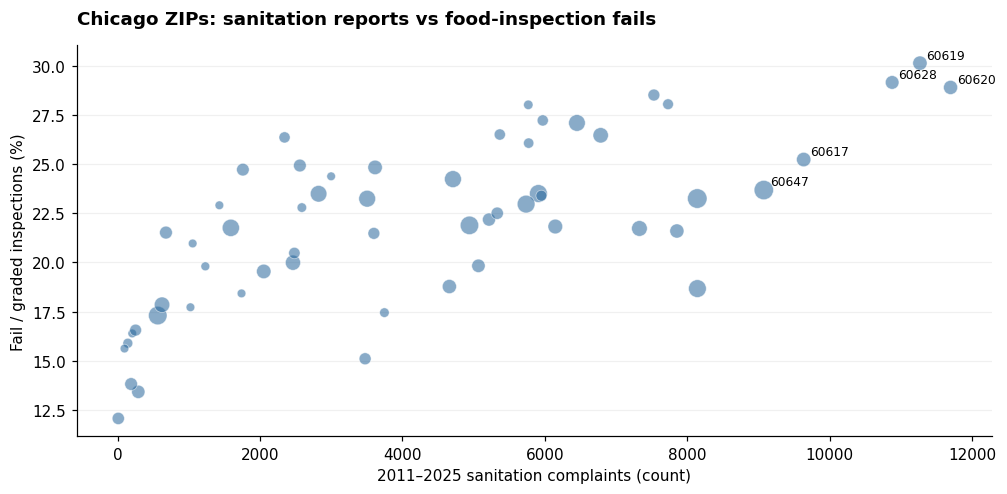

In [2]:
fig,ax=plt.subplots();size=np.clip(zip.graded/55,32,270)
ax.scatter(zip.complaints,zip.fail_pct,s=size,color=BLUE,alpha=.55,edgecolor='white',linewidth=.5)
for _,r in zip.nlargest(5,'complaints').iterrows():ax.annotate(r['zip'],(r.complaints,r.fail_pct),xytext=(4,3),textcoords='offset points',fontsize=8)
style(ax,'Chicago ZIPs: sanitation reports vs food-inspection fails','Fail / graded inspections (%)','2011–2025 sanitation complaints (count)')
print(f"Spearman correlation across {len(zip)} eligible ZIPs: {zip.complaints.corr(zip.fail_pct,method='spearman'):.3f}")
show()

**Interpretation:** Each bubble is a ZIP, sized by its graded inspection sample. Counts are sensitive to population, business density, and 311 usage; do not interpret a ZIP-level relationship as an establishment-level effect.

### Chart 2 | Highest 311-volume ZIP codes

**Question:** Where is the volume of recorded sanitation complaints greatest?

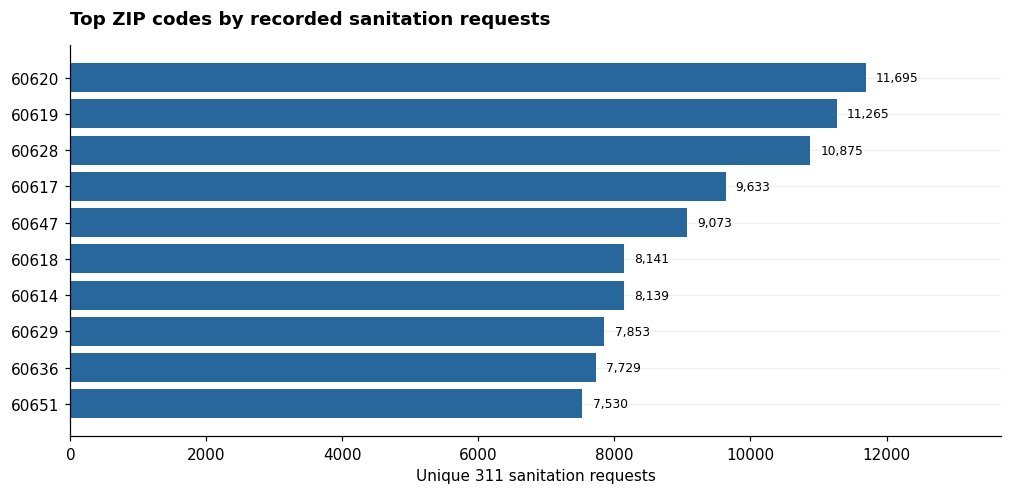

In [3]:
d=zip.nlargest(10,'complaints').sort_values('complaints');fig,ax=plt.subplots();b=ax.barh(d.zip,d.complaints,color=BLUE)
for p,r in builtins.zip(b,d.itertuples()):ax.text(p.get_width()+150,p.get_y()+p.get_height()/2,f'{r.complaints:,}',va='center',fontsize=8)
ax.set_xlim(0,d.complaints.max()*1.17);style(ax,'Top ZIP codes by recorded sanitation requests',xlabel='Unique 311 sanitation requests');show()

**Interpretation:** These are counts rather than complaint rates per resident or per business. They identify where reports are concentrated, not necessarily where food safety is worst.

### Chart 3 | Highest failure-rate ZIP codes

**Question:** Which ZIPs have the highest food-inspection failure rates, with adequate sample sizes?

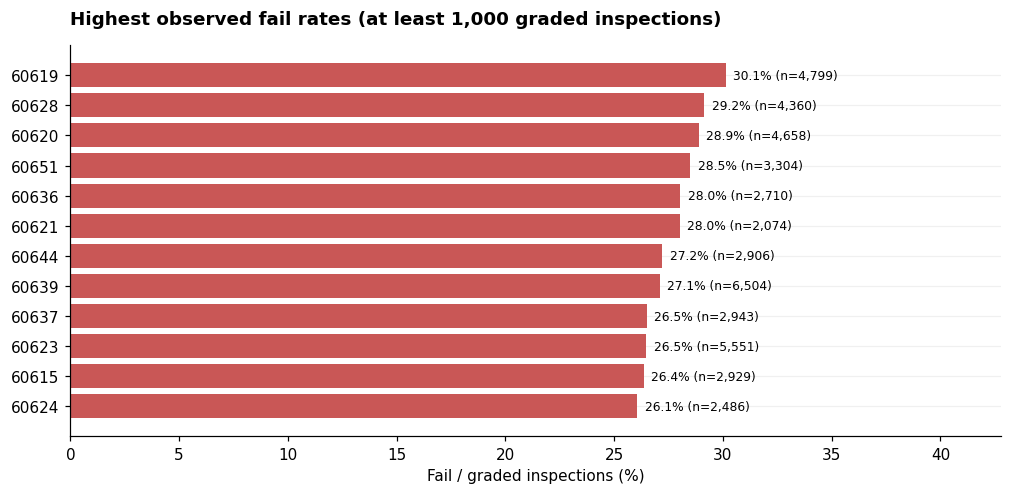

In [4]:
d=zip[zip.graded>=1000].nlargest(12,'fail_pct').sort_values('fail_pct');fig,ax=plt.subplots();bars=ax.barh(d.zip,d.fail_pct,color=RED)
for b,r in builtins.zip(bars,d.itertuples()):ax.text(b.get_width()+.35,b.get_y()+b.get_height()/2,f'{r.fail_pct:.1f}% (n={r.graded:,})',fontsize=8,va='center')
ax.set_xlim(0,d.fail_pct.max()*1.42);style(ax,'Highest observed fail rates (at least 1,000 graded inspections)',xlabel='Fail / graded inspections (%)');show()

**Interpretation:** This changes the denominator to graded inspections and screens out very small ZIP samples. Facility mix and inspection type still need to be controlled.

### Chart 4 | Complaint quartiles vs failure rate

**Question:** Do ZIPs with more sanitation complaints have systematically higher pooled inspection failure rates?

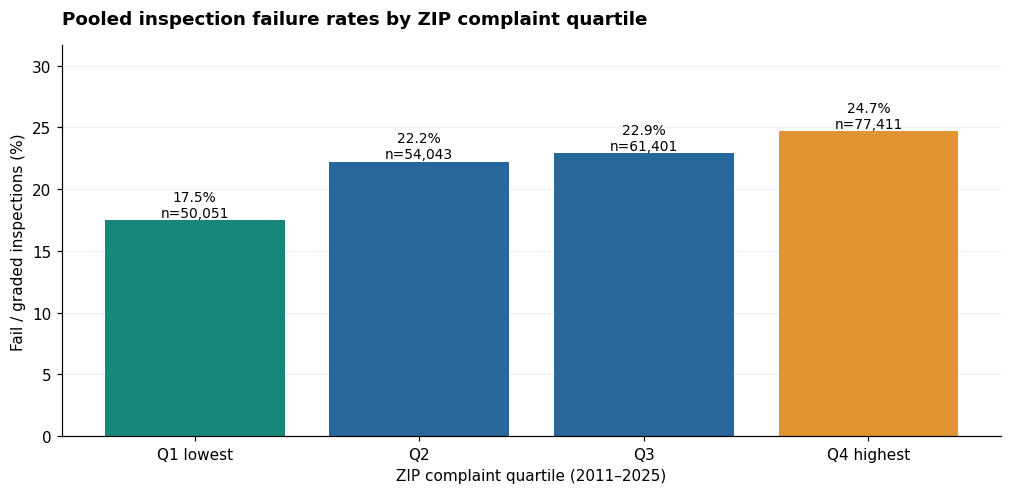

In [5]:
fig,ax=plt.subplots();bars=ax.bar(quartiles.quartile.astype(str),quartiles.fail_pct,color=[TEAL,BLUE,BLUE,ORANGE])
for b,r in builtins.zip(bars,quartiles.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.25,f'{r.fail_pct:.1f}%\nn={r.graded:,}',ha='center',fontsize=9)
ax.set_ylim(0,max(quartiles.fail_pct)*1.28);style(ax,'Pooled inspection failure rates by ZIP complaint quartile','Fail / graded inspections (%)','ZIP complaint quartile (2011–2025)');show()

**Interpretation:** Pooling graded inspections within quartiles weights more frequently inspected ZIPs more heavily. The pattern is descriptive, not a controlled association.

### Chart 5 | Correlation changes by year

**Question:** Is the ZIP-level relationship stable from year to year?

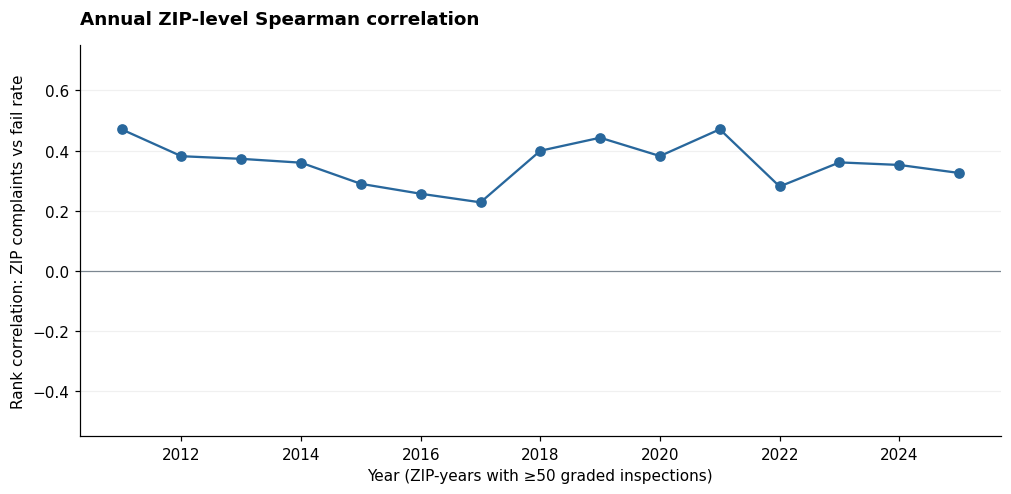

In [6]:
fig,ax=plt.subplots();ax.plot(year_corr.year,year_corr.spearman,marker='o',color=BLUE);ax.axhline(0,color=GREY,linewidth=.8)
ax.set_ylim(-.55,.75);style(ax,'Annual ZIP-level Spearman correlation','Rank correlation: ZIP complaints vs fail rate','Year (ZIP-years with ≥50 graded inspections)');show()

**Interpretation:** The correlation is estimated separately for each year among ZIPs with at least 50 graded inspections. Year-to-year variation warns against using a single citywide correlation as a universal rule.

### Chart 6 | Same-address-year complaint bands

**Question:** Does a more restrictive same-address-year comparison tell a similar story?

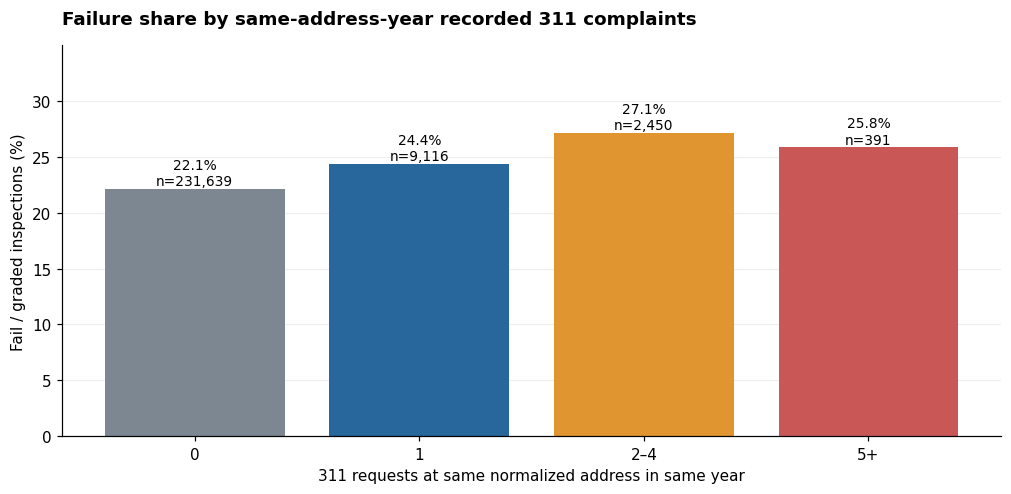

In [7]:
fig,ax=plt.subplots();bars=ax.bar(addr_band.band.astype(str),addr_band.fail_pct,color=[GREY,BLUE,ORANGE,RED])
for b,r in builtins.zip(bars,addr_band.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.35,f'{r.fail_pct:.1f}%\nn={r.graded:,}',ha='center',fontsize=9)
ax.set_ylim(0,max(addr_band.fail_pct)*1.29);style(ax,'Failure share by same-address-year recorded 311 complaints','Fail / graded inspections (%)','311 requests at same normalized address in same year');show()

**Interpretation:** Exact conservative address matches are relatively rare and a shared address is not proof of a complaint about that facility. Same-year joins do **not** establish whether the complaint preceded the inspection.

## Discussion and responsible claims

**Best answer:** Sanitation complaints and food-inspection failure patterns overlap in some ZIPs and address-years, but the evidence is descriptive. A fair conclusion is that combined data can prioritize **questions for further investigation**, not directly rank individual restaurants or prove a causal relationship.

## Key Findings and Business Implications

### Executive takeaway
**Where sanitation complaints are concentrated, graded food-inspection failure rates also tend to be higher across ZIP codes—but the relationship is descriptive, not proof that 311 reports concern individual restaurants or cause inspection failures.** Here “business implications” means potential decisions for city sanitation/public-health teams and inspected establishments.

### Four evidence-backed findings

1. **ZIP-level patterns move together (Chart 1).** Across **57 ZIP codes** with at least 500 graded inspections in 2011–2025, the Spearman rank correlation between 311 complaint **counts** and inspection failure **percentages** is **0.708**. The correlation is unadjusted for population, number of establishments, facility mix, or reporting practices; it must not be interpreted as a restaurant-level effect.
2. **High-volume areas merit joint investigation (Charts 2–3).** ZIP **60620** recorded **11,695** sanitation requests with a **28.9%** failure share among **4,658** graded inspections. ZIP **60619** recorded **11,265** requests and a **30.1%** failure share (**n=4,799** graded inspections).
3. **Co-located reports are associated with a higher observed failure share (Chart 6).** Inspection events at an address with **2–4 recorded 311 reports in the same year** had a **27.1%** failure rate (**n=2,450** graded inspections), compared with **22.1%** (**n=231,639**) where no same-address/year complaint was matched—a **5.0 percentage-point** descriptive difference. An address-year match **does not identify a complaint against that restaurant**.
4. **The relationship needs more careful denominators (Charts 4–5).** Counts of reports are not counts per resident or per food establishment. Before ranking neighborhoods for intervention, the team should calculate complaint rates using defensible denominators and stratify inspections by facility risk and inspection type.

### Business / public-service implications

- **Chicago Department of Public Health (CDPH):** use the ZIP-level pattern to identify areas for *review*, then check whether differences persist after adjusting for the facilities and inspection types actually sampled.
- **311 / sanitation operations:** map complaint hotspots alongside inspection outcomes to decide where data-quality audits, resident outreach, or coordinated follow-up might be useful—not to automatically target businesses.
- **Food establishments:** explain that a ZIP-level failure rate is not a judgment about any individual facility; improvement efforts should rely on its own verified inspection and violation history.

### Recommended next steps

1. Add licensed-food-establishment counts and, where defensible, population denominators for each ZIP; recompute complaint *rates* rather than relying solely on totals.
2. Compare similar facility risk levels and inspection types across ZIPs; consider a multivariable model with uncertainty intervals and minimum sample sizes.
3. Audit a small sample of exact-address matches using facility names, unit numbers, and complaint descriptions before using them operationally.

### Limits and responsible conclusion

This is an **observational ecological analysis of Chicago ZIP codes, 2011–2025**. Inspection selection, residential reporting, geographic denominators, and shared-address ambiguities can confound the association. The evidence supports **investigating geographic overlap**, not saying 311 complaints caused failed inspections or that specific restaurants were implicated.

**Source of values:** the notebook's embedded aggregates, also documented in `aggregated_results/eligible_zip_summary.csv` and `complaint_band_failure_rates.csv` in the complete project package.
